# MoveEasy Per-Delivery Risk Scoring — Exploratory Data Analysis

**Goal of this notebook:** understand `delivery.db` (SQLite, tables `deliveries`
and `feedback`) deeply enough to justify an engineered target column and a
feature set for a per-delivery risk-scoring model that predicts, at dispatch
time, the probability and severity of a service failure (primarily lateness).

Data file used: `.data/delivery.db` (relative to this notebook's location).

## 1. Data Overview

We start by loading both tables, looking at shape/dtypes/first rows, and then
engineering the target column directly from the two timestamp fields every
delivery has (`delivery_datetime` vs `promised_delivery_datetime`). This does
**not** require any of the messy numeric-as-text columns to be cleaned first,
so we do it here to establish up front what kind of ML problem this is —
data-quality cleanup follows in Section 2 and is applied to everything used
from Section 3 onward.

In [1]:
import sqlite3
import numpy as np
import pandas as pd
from scipy import stats

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

DB_PATH = "./data/delivery.db"
con = sqlite3.connect(DB_PATH)
deliveries_raw = pd.read_sql("SELECT * FROM deliveries", con)
feedback_raw = pd.read_sql("SELECT * FROM feedback", con)
con.close()

print("deliveries shape:", deliveries_raw.shape)
print("feedback shape:  ", feedback_raw.shape)

deliveries shape: (150750, 18)
feedback shape:   (54972, 5)


In [2]:
print("=== deliveries dtypes ===")
print(deliveries_raw.dtypes)
print()
print("=== feedback dtypes ===")
print(feedback_raw.dtypes)

=== deliveries dtypes ===
delivery_id                       str
branch                            str
client_id                         str
booking_datetime                  str
pickup_datetime                   str
promised_delivery_datetime        str
delivery_datetime                 str
distance_km                   float64
parcel_weight_kg                  str
parcel_value_sgd                  str
parcel_category                   str
delivery_priority                 str
num_stops_on_route                str
driver_id                         str
driver_experience_months          str
vehicle_type                      str
payment_method                    str
recipient_postal_code             str
dtype: object

=== feedback dtypes ===
feedback_id              str
delivery_id              str
rating               float64
comment                  str
feedback_datetime        str
dtype: object


**Observation:** every column in `deliveries` came in as `object`/text except
`distance_km`, even columns that are semantically numeric
(`parcel_weight_kg`, `parcel_value_sgd`, `num_stops_on_route`,
`driver_experience_months`, `recipient_postal_code`). That is itself a data
quality signal worth digging into in Section 2 — SQLite has no enforced
column typing, so text contamination in a numeric column silently produces an
`object` dtype instead of an error.

In [3]:
print("=== deliveries.head() ===")
display(deliveries_raw.head())

=== deliveries.head() ===


,delivery_id,branch,client_id,booking_datetime,pickup_datetime,promised_delivery_datetime,delivery_datetime,distance_km,parcel_weight_kg,parcel_value_sgd,parcel_category,delivery_priority,num_stops_on_route,driver_id,driver_experience_months,vehicle_type,payment_method,recipient_postal_code
0,D2026000000,North,C0000,2026-01-17 16:10:11.419632,2026-01-17 18:14:42.141079,2026-01-18 00:10:11.419632,2026-01-17 23:58:29.106853,5.86,0.585,102.05,standard,Standard,62.0,DRV0130,2.0,van,prepaid,57
1,D2026000001,North,C0007,2025-12-06 15:33:02.496777,2025-12-06 16:11:03.931680,2025-12-06 19:33:02.496777,2025-12-06 18:53:45.937422,3.10,3.292,105.17,standard,Express,NaN,DRV0087,33.0,van,cod,73
2,D2026000002,East,C0000,2026-04-20 16:32:08.934038,2026-04-20 19:54:14.157180,2026-04-21 00:32:08.934038,2026-04-21 00:06:28.451910,8.03,1.426,36.48,standard,Standard,35.0,DRV0040,35.0,van,cod,51
3,D2026000003,East,C0002,2026-05-11 12:15:01.850095,2026-05-11 14:44:34.713623,2026-05-11 20:15:01.850095,2026-05-11 21:29:30.086468,6.06,2.163,71.8,fragile,Standard,90.0,DRV0109,9.0,van,prepaid,49
4,D2026000004,North,C0009,2026-05-20 14:32:47.616722,2026-05-20 15:50:24.743132,2026-05-20 18:32:47.616722,2026-05-20 17:46:23.101404,4.65,0.7,18.05,standard,Express,54.0,DRV0085,24.0,bike,prepaid,73


In [4]:
print("=== feedback.head() ===")
display(feedback_raw.head())

=== feedback.head() ===


,feedback_id,delivery_id,rating,comment,feedback_datetime
0,F01000000,D2026000001,5.0,"On time as always, thanks! Driver very polite, can!",2025-12-07 02:17:46.889241
1,F01000001,D2026000003,3.0,Delivery was acceptable.,2026-05-12 11:00:52.289329
2,F01000002,D2026000011,5.0,"Great experience, no complaints.",2026-04-11 08:19:49.177079
3,F01000003,D2026000012,5.0,,2025-12-31 11:57:23.657124
4,F01000004,D2026000013,4.0,,2026-02-24 04:52:01.214870


In [5]:
# Engineer the target directly from the two datetime columns every row has.
d = deliveries_raw.copy()
for c in ["booking_datetime", "pickup_datetime", "promised_delivery_datetime", "delivery_datetime"]:
    d[c] = pd.to_datetime(d[c], errors="coerce")

d["lateness_minutes"] = (d["delivery_datetime"] - d["promised_delivery_datetime"]).dt.total_seconds() / 60
d["is_late"] = (d["lateness_minutes"] > 0).astype(int)

print("Target: lateness_minutes (continuous, minutes late; negative = early)")
print(d["lateness_minutes"].describe())
print()
print(f"Derived binary view is_late (lateness_minutes > 0): {d['is_late'].mean():.2%} positive class")

Target: lateness_minutes (continuous, minutes late; negative = early)
count    150750.000000
mean         -9.245044
std          51.608206
min        -430.583646
25%         -30.793105
50%         -17.295718
75%          -6.052429
max        1562.834229
Name: lateness_minutes, dtype: float64

Derived binary view is_late (lateness_minutes > 0): 10.97% positive class


**What kind of problem is this?**

The business objective asks for *both* a probability of failure and an
estimated severity, at dispatch time. A single continuous target,
**`lateness_minutes`** (delivery time minus promised time, in minutes),
naturally supports both:

- **Regression** on `lateness_minutes` directly gives an estimated severity
  (and its sign/threshold gives the probability view).
- Thresholding it at `> 0` gives **`is_late`**, a binary classification view
  with roughly an **11% positive rate** — i.e. this is a moderately
  imbalanced binary problem if modelled as classification, or a
  right-skewed continuous target if modelled as regression (confirmed
  formally in Section 3).

For this EDA, `lateness_minutes` is used as the primary `[TARGET_COLUMN]`
for correlation/association work in Sections 5–8, since it is strictly more
informative than the binarised version (it also captures *how* early or late
a delivery is, which is what "severity" means for this problem) — the binary
`is_late` view is reported alongside it wherever it adds a directly
business-readable number (e.g. "% late" by category).

We will revisit and validate this target choice against the independent
`feedback.rating` signal at the end of this section.

In [6]:
# Sanity-check the target against customer feedback: do later deliveries
# actually get worse ratings? This validates that lateness is a reasonable
# proxy for "service failure" as perceived by the customer.
fb = feedback_raw.copy()
fb["rating"] = pd.to_numeric(fb["rating"], errors="coerce")
fb["feedback_datetime"] = pd.to_datetime(fb["feedback_datetime"], errors="coerce")

# a delivery can have >1 feedback row (checked in Section 2); take the latest one per delivery
fb_dedup = fb.sort_values("feedback_datetime").drop_duplicates("delivery_id", keep="last")

merged = d[["delivery_id", "lateness_minutes", "is_late"]].merge(
    fb_dedup[["delivery_id", "rating"]], on="delivery_id", how="inner"
)
print(f"Deliveries with a matched feedback rating: {len(merged):,} of {len(d):,}"
      f" ({len(merged)/len(d):.1%})")

late_rating = merged.loc[merged["is_late"] == 1, "rating"].mean()
ontime_rating = merged.loc[merged["is_late"] == 0, "rating"].mean()
r, p = stats.pearsonr(merged["lateness_minutes"].fillna(0), merged["rating"].fillna(merged["rating"].mean()))
print(f"Mean rating | late deliveries:    {late_rating:.2f}")
print(f"Mean rating | on-time deliveries: {ontime_rating:.2f}")
print(f"Pearson r(lateness_minutes, rating) = {r:.3f} (p={p:.2e})")

Deliveries with a matched feedback rating: 54,994 of 150,750 (36.5%)
Mean rating | late deliveries:    2.97
Mean rating | on-time deliveries: 4.63
Pearson r(lateness_minutes, rating) = -0.527 (p=0.00e+00)


**Observation:** late deliveries get meaningfully worse ratings than on-time
ones, and the correlation between minutes-late and rating is negative and
statistically significant. This supports using lateness as the primary
engineered target — it is a real, independently-verifiable proxy for the
service-quality problem MoveEasy is trying to fix, not an arbitrary choice.
Note this feedback data is **post-delivery** and cannot be used as a *model
input feature* (it doesn't exist at dispatch time) — it is used here purely
to validate the target definition, a point we return to in Section 9.

## 2. Data Quality

We check, one at a time: missing values, duplicate records, mixed/incorrect
types, casing inconsistencies in categoricals, and impossible values —
rather than assuming any of these are absent.

In [7]:
print("=== Missing values: deliveries ===")
miss = deliveries_raw.isna().sum().to_frame("n_missing")
miss["pct_missing"] = (miss["n_missing"] / len(deliveries_raw) * 100).round(2)
display(miss[miss["n_missing"] > 0].sort_values("n_missing", ascending=False))

=== Missing values: deliveries ===


,n_missing,pct_missing
num_stops_on_route,6135,4.07
vehicle_type,6116,4.06
payment_method,6035,4.00
parcel_value_sgd,5998,3.98
recipient_postal_code,5939,3.94
parcel_weight_kg,5907,3.92
driver_experience_months,5896,3.91


In [8]:
print("=== Missing values: feedback ===")
miss_fb = feedback_raw.isna().sum().to_frame("n_missing")
miss_fb["pct_missing"] = (miss_fb["n_missing"] / len(feedback_raw) * 100).round(2)
display(miss_fb[miss_fb["n_missing"] > 0].sort_values("n_missing", ascending=False))

=== Missing values: feedback ===


,n_missing,pct_missing
rating,2241,4.08
comment,2194,3.99


**Observation:** six columns in `deliveries` each carry ~4% missingness
(`parcel_weight_kg`, `parcel_value_sgd`, `num_stops_on_route`,
`driver_experience_months`, `vehicle_type`, `payment_method`,
`recipient_postal_code`) — a similar rate across unrelated columns is
consistent with independent random corruption rather than a structural
pattern tied to one column. In `feedback`, `rating` is missing for ~4% of
rows and `comment` is frequently blank (checked below) but not `NaN`-coded.

In [9]:
empty_comment_pct = (feedback_raw["comment"].fillna("").str.strip() == "").mean()
print(f"Feedback rows with a blank comment: {empty_comment_pct:.1%}")

Feedback rows with a blank comment: 20.8%


In [10]:
print("=== Duplicate records ===")
print(f"Fully duplicate rows in deliveries:      {deliveries_raw.duplicated().sum():,}")
print(f"Duplicate delivery_id values:            {deliveries_raw['delivery_id'].duplicated().sum():,}")
print(f"Duplicate feedback_id values:            {feedback_raw['feedback_id'].duplicated().sum():,}")
print(f"delivery_id values with >1 feedback row: {(feedback_raw['delivery_id'].value_counts() > 1).sum():,}")

=== Duplicate records ===
Fully duplicate rows in deliveries:      750
Duplicate delivery_id values:            750
Duplicate feedback_id values:            273
delivery_id values with >1 feedback row: 273


**Observation:** every duplicated `delivery_id` corresponds to a fully
duplicated row (750 exact copies) — straightforward to drop. Feedback is
different: 273 `delivery_id`s have more than one feedback row, and (checked
below) these are not identical duplicates — they look like a customer
submitting an updated/second rating for the same delivery, so the right fix
there is "keep latest by `feedback_datetime`", not "drop".

In [11]:
dup_delivery_ids = feedback_raw.loc[feedback_raw["delivery_id"].duplicated(keep=False), "delivery_id"].unique()[:1]
display(feedback_raw[feedback_raw["delivery_id"].isin(dup_delivery_ids)].sort_values("feedback_datetime"))

,feedback_id,delivery_id,rating,comment,feedback_datetime
173,F01000173,D2026000494,5.0,Polite and professional driver.,2026-05-25 21:50:23.155392
54931,F01000173,D2026000494,5.0,Polite and professional driver.,2026-05-25 21:50:23.155392


In [12]:
print("=== Structural issue: numeric columns stored as text ===")
numeric_as_text_cols = ["parcel_weight_kg", "parcel_value_sgd", "num_stops_on_route",
                         "driver_experience_months", "recipient_postal_code"]
for c in numeric_as_text_cols:
    coerced = pd.to_numeric(deliveries_raw[c], errors="coerce")
    non_numeric_non_null = deliveries_raw[c].notna().sum() - coerced.notna().sum()
    print(f"{c:28s} dtype={str(deliveries_raw[c].dtype):8s}  "
          f"non-numeric-but-present entries: {non_numeric_non_null}")

=== Structural issue: numeric columns stored as text ===
parcel_weight_kg             dtype=str       non-numeric-but-present entries: 0
parcel_value_sgd             dtype=str       non-numeric-but-present entries: 0
num_stops_on_route           dtype=str       non-numeric-but-present entries: 0
driver_experience_months     dtype=str       non-numeric-but-present entries: 0
recipient_postal_code        dtype=str       non-numeric-but-present entries: 0


**Observation:** the "text" dtype on these five columns is not due to
genuinely non-numeric entries (every present value parses cleanly as a
number) — it's an artefact of SQLite's column-level type flexibility, likely
because the column also contains `NULL`s stored inconsistently. They are safe
to coerce to numeric directly. `recipient_postal_code` is numeric-looking but
semantically a zone identifier, so it is treated as **categorical**, not a
continuous numeric feature, for the rest of this notebook.

In [13]:
print("=== Structural issue: casing / typo inconsistencies in categoricals ===")
for c in ["branch", "parcel_category", "vehicle_type"]:
    print(f"--- {c} ---")
    print(deliveries_raw[c].value_counts(dropna=False))
    print()

=== Structural issue: casing / typo inconsistencies in categoricals ===
--- branch ---
branch
Central    44947
East       37343
West       34635
North      32940
Cnetral      275
west         214
EAST         211
Noth         185
Name: count, dtype: int64

--- parcel_category ---
parcel_category
standard        112297
fragile          19406
oversized        12142
refrigerated      6019
Standard           664
Fragile            123
over-sized          64
refrig.             35
Name: count, dtype: int64

--- vehicle_type ---
vehicle_type
van       83438
bike      45876
truck     14409
NaN        6116
VAN         539
Bike        291
truck        81
Name: count, dtype: int64



**Observation:** `branch` has 4 real depots but 4 extra noisy variants
(`Cnetral`, `west`, `EAST`, `Noth`) that are typos/casing of the same 4
values — about 0.6% of rows. `parcel_category` similarly has casing
duplicates (`Standard`, `Fragile`) and inconsistent spelling
(`over-sized`, `refrig.`) for existing categories — no new categories are
hiding here, all collapse cleanly onto the 4 canonical values. `vehicle_type`
has case-duplicates of the same 3 vehicle classes. `delivery_priority` and
`payment_method` (checked implicitly via Section 4) do **not** show this
problem — the inconsistency is specific to `branch`, `parcel_category`, and
`vehicle_type`.

In [14]:
print("=== Structural issue: impossible (negative) values in count/measure columns ===")
for c in numeric_as_text_cols:
    coerced = pd.to_numeric(deliveries_raw[c], errors="coerce")
    n_neg = (coerced < 0).sum()
    print(f"{c:28s} negative-valued entries: {n_neg:5d}  (min={coerced.min()})")

=== Structural issue: impossible (negative) values in count/measure columns ===
parcel_weight_kg             negative-valued entries:  2178  (min=-1.0)
parcel_value_sgd             negative-valued entries:  2245  (min=-1.0)
num_stops_on_route           negative-valued entries:  2154  (min=-1.0)
driver_experience_months     negative-valued entries:  2163  (min=-1.0)
recipient_postal_code        negative-valued entries:     0  (min=1.0)


**Observation:** each of `parcel_weight_kg`, `parcel_value_sgd`,
`num_stops_on_route`, `driver_experience_months` has ~2,150–2,250 rows valued
at exactly **-1**, a classic missing-value sentinel rather than a real
measurement (a delivery cannot weigh -1kg or have -1 stops on its route).
`recipient_postal_code` has none. These `-1`s will be recoded to `NaN` in
cleaning below — treating them as real values would badly distort the
descriptive statistics in Section 3.

In [15]:
print("=== Datetime logic checks ===")
n_pickup_before_booking = (d["pickup_datetime"] < d["booking_datetime"]).sum()
n_delivery_before_pickup = (d["delivery_datetime"] < d["pickup_datetime"]).sum()
n_promised_before_booking = (d["promised_delivery_datetime"] < d["booking_datetime"]).sum()
print(f"pickup before booking:   {n_pickup_before_booking}")
print(f"delivery before pickup:  {n_delivery_before_pickup}")
print(f"promised before booking: {n_promised_before_booking}")
print()
print("booking_datetime range:", d["booking_datetime"].min(), "to", d["booking_datetime"].max())
print("delivery_datetime range:", d["delivery_datetime"].min(), "to", d["delivery_datetime"].max())

=== Datetime logic checks ===
pickup before booking:   0
delivery before pickup:  478
promised before booking: 0

booking_datetime range: 2025-11-28 09:29:14.089554 to 2026-05-27 18:48:57.606314
delivery_datetime range: 2025-11-28 11:10:07.752563 to 2026-05-28 06:26:18.454618


**Observation:** booking → pickup → promised ordering is always respected,
but 478 rows (~0.3%) show `delivery_datetime` before `pickup_datetime` —
physically impossible (a parcel can't be delivered before it's picked up).
These are treated as corrupted timestamps and excluded from target-bearing
analysis below, since they'd produce a nonsensical (large negative)
`lateness_minutes`.

In [16]:
# ---- Build the cleaned analysis dataframe used from here on ----
d = deliveries_raw.copy()
for c in ["booking_datetime", "pickup_datetime", "promised_delivery_datetime", "delivery_datetime"]:
    d[c] = pd.to_datetime(d[c], errors="coerce")

# 1) drop exact duplicate rows
before = len(d)
d = d.drop_duplicates().reset_index(drop=True)
print(f"Dropped {before - len(d)} exact duplicate rows -> {len(d):,} rows")

# 2) drop rows with impossible datetime ordering (delivery before pickup)
before = len(d)
d = d[d["delivery_datetime"] >= d["pickup_datetime"]].reset_index(drop=True)
print(f"Dropped {before - len(d)} rows with delivery_datetime < pickup_datetime -> {len(d):,} rows")

# 3) standardize categorical casing/typos
branch_map = {"cnetral": "Central", "central": "Central", "west": "West",
              "east": "East", "noth": "North", "north": "North"}
d["branch"] = d["branch"].str.strip().str.lower().map(branch_map)

cat_map = {"standard": "standard", "fragile": "fragile", "over-sized": "oversized",
           "oversized": "oversized", "refrig.": "refrigerated", "refrigerated": "refrigerated"}
d["parcel_category"] = d["parcel_category"].str.strip().str.lower().map(cat_map)

d["vehicle_type"] = d["vehicle_type"].str.strip().str.lower()
d["payment_method"] = d["payment_method"].str.strip().str.lower()
d["delivery_priority"] = d["delivery_priority"].str.strip()

# 4) coerce numeric-as-text columns, recode -1 sentinels (and any other negatives) to NaN
for c in numeric_as_text_cols:
    d[c] = pd.to_numeric(d[c], errors="coerce")
    d.loc[d[c] < 0, c] = np.nan

d["recipient_postal_code"] = d["recipient_postal_code"].astype("Int64").astype("string")

# 5) re-engineer the target on the cleaned frame
d["lateness_minutes"] = (d["delivery_datetime"] - d["promised_delivery_datetime"]).dt.total_seconds() / 60
d["is_late"] = (d["lateness_minutes"] > 0).astype(int)

print()
print("Final cleaned shape:", d.shape)
print(f"is_late positive rate: {d['is_late'].mean():.2%}")
NUMERIC_FEATURES = ["distance_km", "parcel_weight_kg", "parcel_value_sgd",
                     "num_stops_on_route", "driver_experience_months"]
CATEGORICAL_FEATURES = ["branch", "parcel_category", "delivery_priority",
                         "vehicle_type", "payment_method", "recipient_postal_code"]
TARGET = "lateness_minutes"

Dropped 750 exact duplicate rows -> 150,000 rows
Dropped 474 rows with delivery_datetime < pickup_datetime -> 149,526 rows

Final cleaned shape: (149526, 20)
is_late positive rate: 11.00%


All analysis from Section 3 onward uses this cleaned `d` dataframe, the
five numeric predictors and six categorical predictors listed above, and
`lateness_minutes` as `[TARGET_COLUMN]`.

## 3. Descriptive Statistics

Beyond mean/std, we look at skewness and (excess) kurtosis for every numeric
column, including the target, since these drive transformation/outlier
decisions later.

In [17]:
num_cols_for_stats = NUMERIC_FEATURES + [TARGET]
desc = d[num_cols_for_stats].describe().T
desc["skew"] = d[num_cols_for_stats].skew()
desc["kurtosis_excess"] = d[num_cols_for_stats].kurt()
desc["missing_pct"] = d[num_cols_for_stats].isna().mean() * 100
display(desc.round(3))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis_excess,missing_pct
distance_km,149526.0,5.752,3.388,0.48,3.420,4.950,7.170,30.000,1.839,5.649,0.000
parcel_weight_kg,141506.0,2.236,2.438,0.05,0.815,1.492,2.747,30.000,3.719,22.963,5.364
parcel_value_sgd,141333.0,82.098,125.612,3.00,21.350,44.660,94.060,5000.000,7.504,129.399,5.479
num_stops_on_route,141300.0,44.893,16.827,5.00,33.000,43.000,55.000,90.000,0.515,-0.072,5.501
driver_experience_months,141538.0,17.949,16.623,0.00,7.000,13.000,23.000,120.000,2.542,9.046,5.342
lateness_minutes,149526.0,-8.515,49.697,-107.52,-30.635,-17.221,-6.020,1562.834,4.288,36.218,0.000


**Observation:**

- `lateness_minutes` (the target) has skew far above 1 and very large excess
  kurtosis — a long right tail of badly-late deliveries sitting on top of a
  mass of on-time/early ones. This confirms the earlier design choice to
  prefer **Spearman over Pearson** and non-parametric tests (e.g.
  Mann-Whitney) wherever the target is involved, since Pearson/t-tests
  assume roughly symmetric, thin-tailed data.
- `parcel_value_sgd` and `parcel_weight_kg` are both strongly right-skewed
  (a few high-value/heavy parcels), typical of parcel logistics data (most
  parcels are small/cheap, a minority are large/expensive).
- `distance_km`, `num_stops_on_route`, and `driver_experience_months` are
  much closer to symmetric (skew near 0–1), so Pearson correlation is more
  trustworthy for these specifically.
- `driver_experience_months` and `num_stops_on_route` still carry ~4%
  missingness post-cleaning (the recoded `-1` sentinels) — a real gap to
  handle at modelling time (Section 9), not an EDA artefact.

In [18]:
for c in CATEGORICAL_FEATURES:
    print(f"--- {c} ({d[c].nunique()} categories, {d[c].isna().sum()} missing) ---")
    print(d[c].value_counts(dropna=False).head(10))
    print()

--- branch (4 categories, 0 missing) ---
branch
Central    44872
East       37257
West       34563
North      32834
Name: count, dtype: int64

--- parcel_category (4 categories, 0 missing) ---
parcel_category
standard        112024
fragile          19363
oversized        12126
refrigerated      6013
Name: count, dtype: int64

--- delivery_priority (4 categories, 0 missing) ---
delivery_priority
Standard    82536
Express     41619
Premium     19355
VIP          6016
Name: count, dtype: int64

--- vehicle_type (3 categories, 6062 missing) ---
vehicle_type
van      83314
bike     45785
truck    14365
NaN       6062
Name: count, dtype: int64

--- payment_method (2 categories, 5981 missing) ---
payment_method
prepaid    126189
cod         17356
NaN          5981
Name: count, dtype: int64

--- recipient_postal_code (37 categories, 5890 missing) ---
recipient_postal_code
22      6662
<NA>    5890
76      4636
77      4601
56      4569
73      4525
47      4525
49      4506
52      4501
46    

**Observation:** `branch` (4), `parcel_category` (4), `delivery_priority`
(4), `vehicle_type` (3), `payment_method` (2) are all low-cardinality and
usable directly in a model or a pivot table. `recipient_postal_code` has 37
distinct zones with a long tail of low-count zones — usable as a categorical
feature but too granular for a clean pivot-table interaction view, so it's
used in aggregate (grouped) form rather than cell-by-cell later on.

## 4. Univariate Analysis

Distribution of every numeric and categorical column (including the
target), each followed by an interpretation.

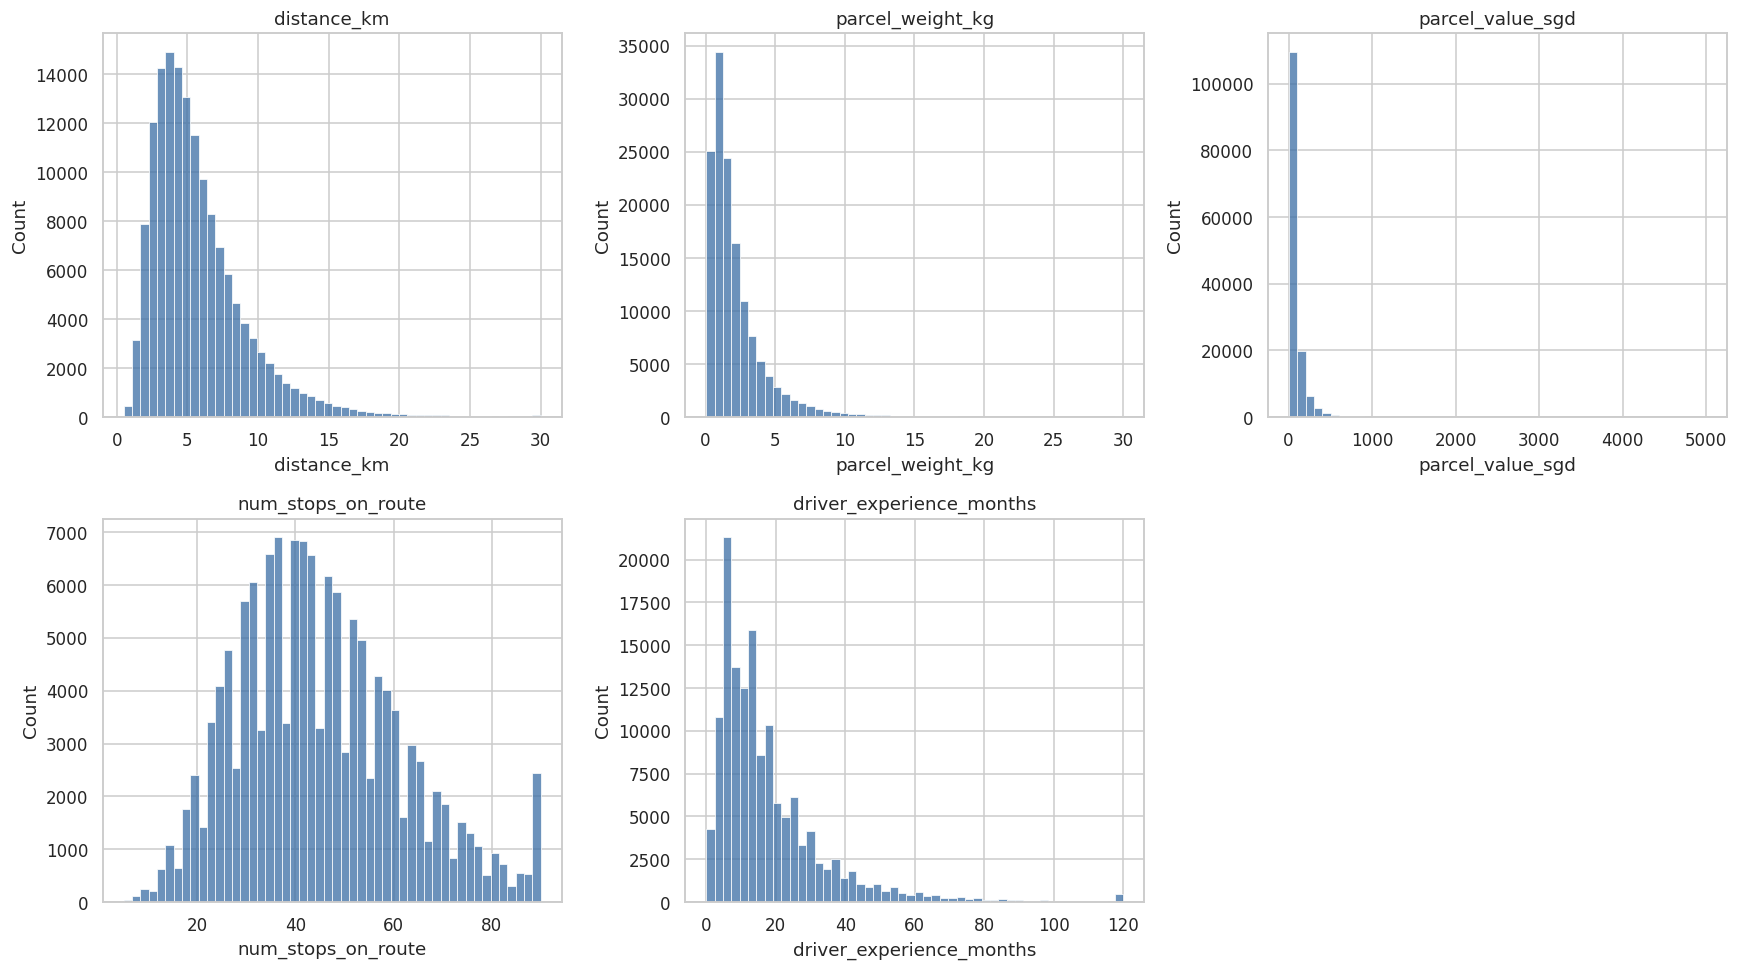

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
for i, c in enumerate(NUMERIC_FEATURES):
    sns.histplot(d[c].dropna(), bins=50, ax=axes[i], color="#3b6ea5")
    axes[i].set_title(c)
axes[5].axis("off")
plt.tight_layout()
plt.show()

**Observation:**

- `distance_km` is right-skewed with most deliveries under ~10km — expected
  for a dense, last-mile city network (Singapore).
- `parcel_weight_kg` and `parcel_value_sgd` both show a sharp peak near zero
  and a long thin tail — consistent with the skew/kurtosis numbers above;
  the vast majority of parcels are small/cheap with occasional bulky/high
  value outliers.
- `num_stops_on_route` looks close to a broad, roughly bell-shaped
  distribution centered around 40–45 stops — this is a route-planning
  variable, not a delivery-specific one, so its spread reflects dispatch
  policy rather than individual delivery variation.
- `driver_experience_months` is right-skewed toward junior drivers (a large
  contracted gig-driver pool with a few long-tenured full-timers is
  consistent with the stated ~200-driver mixed fleet).

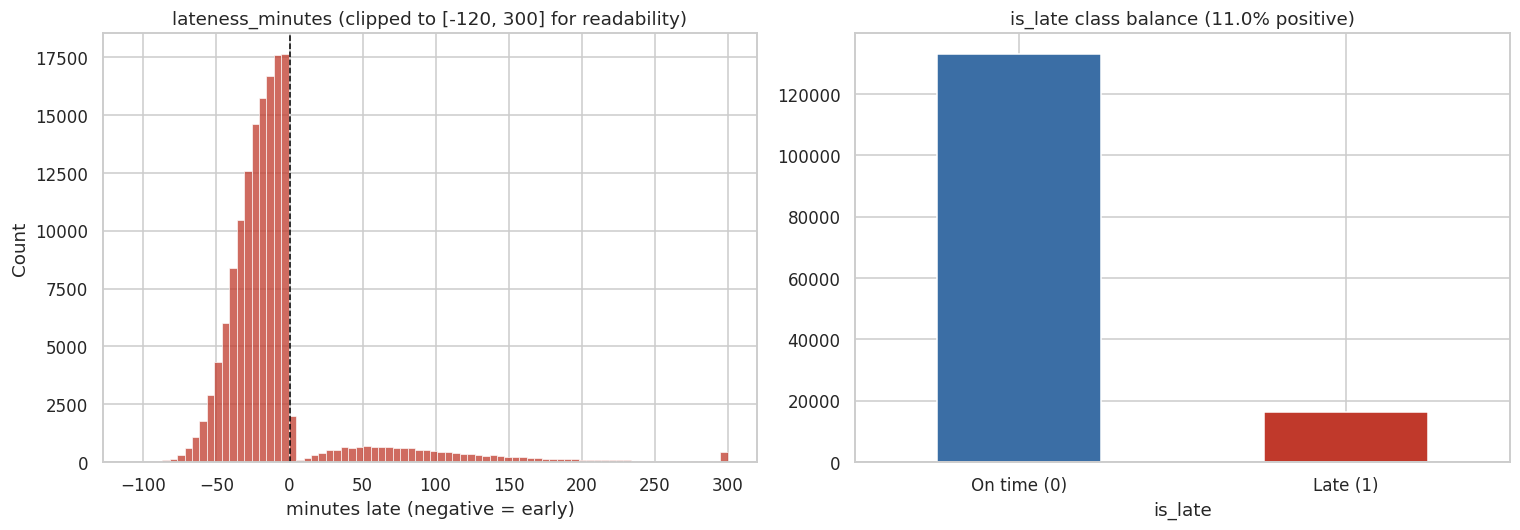

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(d[TARGET].clip(-120, 300), bins=80, ax=ax[0], color="#c0392b")
ax[0].axvline(0, color="black", linestyle="--", linewidth=1)
ax[0].set_title("lateness_minutes (clipped to [-120, 300] for readability)")
ax[0].set_xlabel("minutes late (negative = early)")

d["is_late"].value_counts().sort_index().plot(
    kind="bar", ax=ax[1], color=["#3b6ea5", "#c0392b"]
)
ax[1].set_xticks([0, 1])
ax[1].set_xticklabels(["On time (0)", "Late (1)"], rotation=0)
ax[1].set_title(f"is_late class balance ({d['is_late'].mean():.1%} positive)")
plt.tight_layout()
plt.show()

**Observation:** the bulk of deliveries land noticeably *before* the
promised time (median around -17 minutes), meaning MoveEasy's promise
windows are, on average, padded with buffer — but the right tail extends
past 1,500 minutes late, and as a binary problem the positive class
(`is_late`) is a **minority class at ~11%**. Any classifier trained on
`is_late` will need class-imbalance handling (class weights, resampling, or
threshold tuning); the regression view of `lateness_minutes` avoids that
issue but must contend with the heavy right tail confirmed in Section 3.

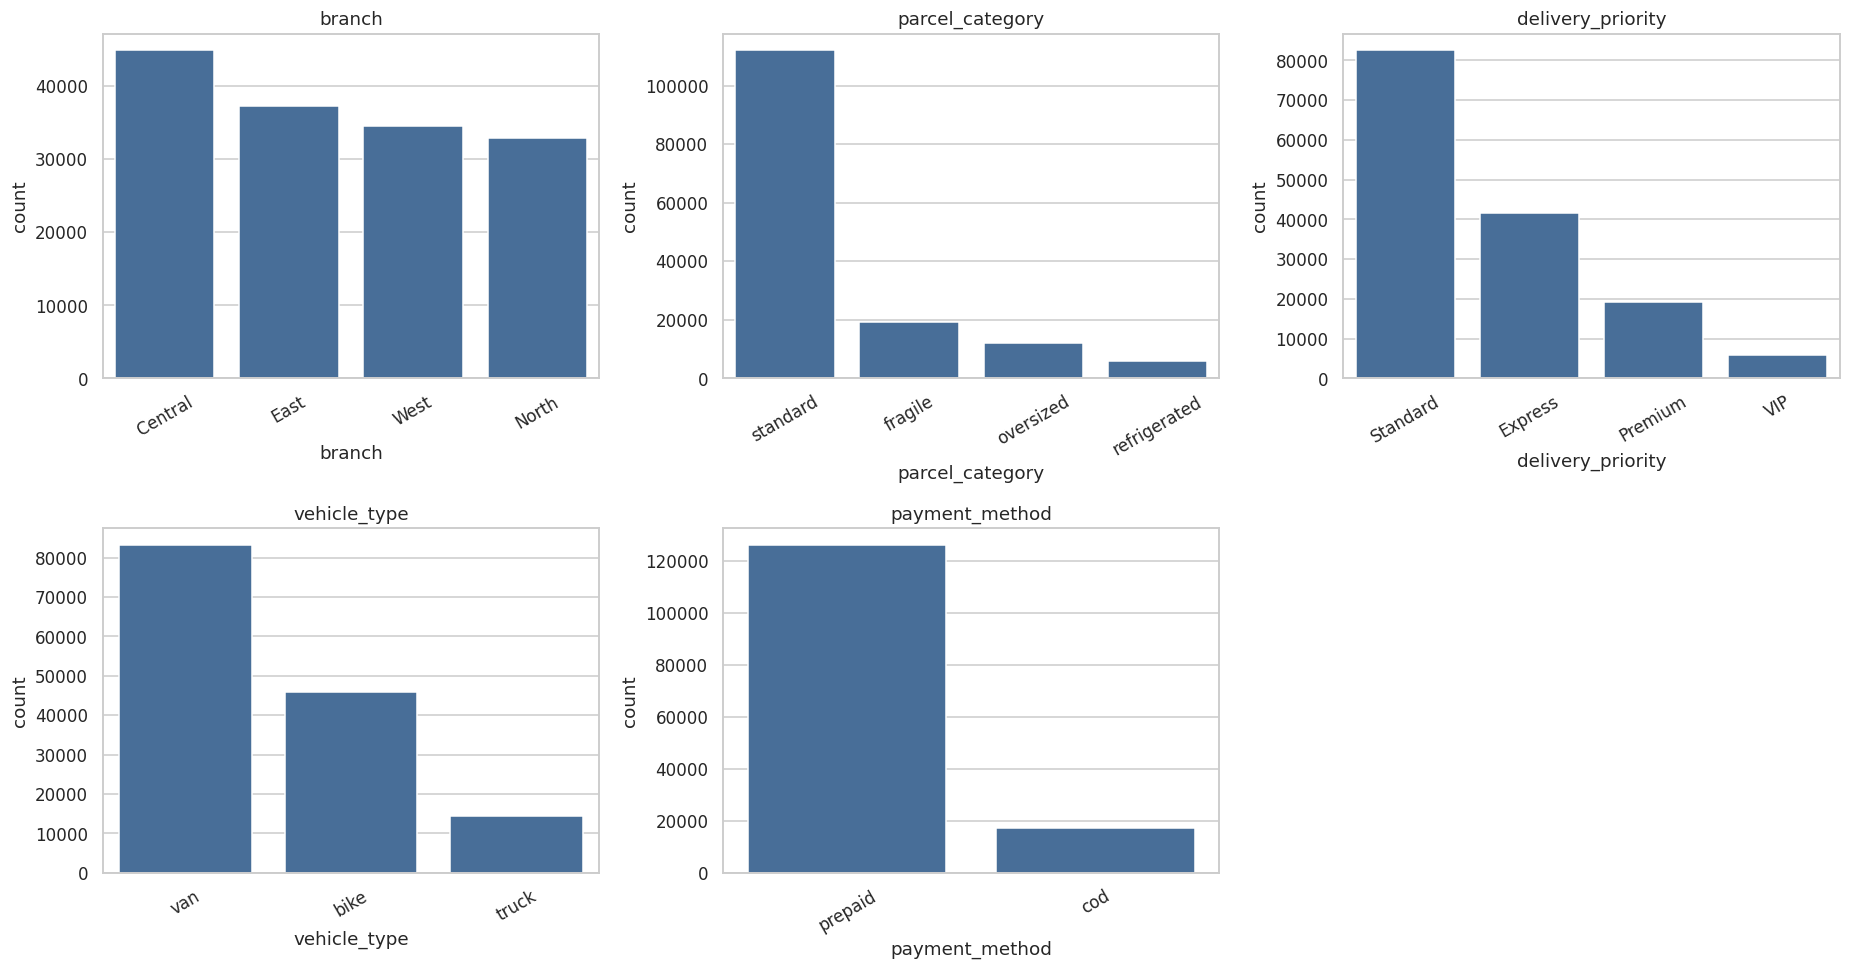

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.ravel()
for i, c in enumerate(CATEGORICAL_FEATURES[:5]):
    order = d[c].value_counts().index
    sns.countplot(data=d, x=c, order=order, ax=axes[i], color="#3b6ea5")
    axes[i].set_title(c)
    axes[i].tick_params(axis="x", rotation=30)
axes[5].axis("off")
plt.tight_layout()
plt.show()

**Observation:**

- `branch`: Central handles noticeably more volume than the other three
  depots — any branch-level lateness differences (Section 6) need to be read
  alongside this volume imbalance, since a small branch's rate estimate is
  noisier.
- `parcel_category`: dominated by `standard` parcels (~75%), with `fragile`,
  `oversized`, and `refrigerated` each a meaningful but much smaller
  minority — the latter two are also the categories most likely to need
  special handling time, worth watching in Section 6.
- `delivery_priority`: `Standard` dominates, `VIP` is the smallest tier
  (~4%) — exactly the tier where a wrong prediction is costliest, and also
  the one with the least data to learn from.
- `vehicle_type`: vans handle the most deliveries, followed by bikes, then
  trucks — likely tracks parcel category (trucks for oversized/refrigerated,
  bikes for small/light standard parcels), tested formally in Section 7.
- `payment_method`: `prepaid` strongly dominates over `cod`. COD handling at
  the door is a plausible lateness driver a priori — tested formally in
  Section 6, where it turns out **not** to hold up.

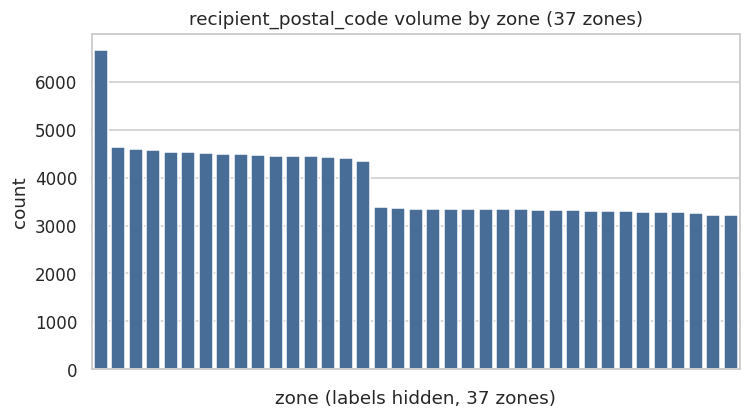

In [22]:
fig, ax = plt.subplots(figsize=(7, 4))
order = d["recipient_postal_code"].value_counts().index
sns.countplot(data=d, x="recipient_postal_code", order=order, ax=ax, color="#3b6ea5")
ax.set_title("recipient_postal_code volume by zone (37 zones)")
ax.set_xticklabels([])
ax.set_xlabel("zone (labels hidden, 37 zones)")
plt.tight_layout()
plt.show()

**Observation:** delivery volume across the 37 postal zones follows a
long-tail pattern — a handful of zones account for a disproportionate share
of deliveries, with many zones seeing comparatively few. Any zone-level
lateness signal will be much noisier for the low-volume zones.

## 5. Bivariate Analysis — Numeric & Categorical Features vs Target

For every numeric feature: Pearson (linear) **and** Spearman (monotonic
rank) correlation against `lateness_minutes`. For every categorical feature:
a one-way ANOVA F-statistic and eta-squared (effect size). Then, for any
feature that looks weak on *both* Pearson and Spearman, an explicit
non-monotonic check (binned mean profile + quadratic-vs-linear R²).

In [23]:
rows = []
for c in NUMERIC_FEATURES:
    sub = d[[c, TARGET]].dropna()
    pear_r, pear_p = stats.pearsonr(sub[c], sub[TARGET])
    spear_r, spear_p = stats.spearmanr(sub[c], sub[TARGET])
    rows.append({
        "feature": c, "n": len(sub),
        "pearson_r": pear_r, "pearson_p": pear_p,
        "spearman_r": spear_r, "spearman_p": spear_p,
        "abs_gap (spearman-pearson)": abs(spear_r) - abs(pear_r),
    })
corr_table = pd.DataFrame(rows).sort_values("abs_gap (spearman-pearson)", ascending=False)
display(corr_table.round(4))

,feature,n,pearson_r,pearson_p,spearman_r,spearman_p,abs_gap (spearman-pearson)
2,parcel_value_sgd,141333,0.0010,0.7158,0.0035,0.1912,0.0025
1,parcel_weight_kg,141506,0.0036,0.1758,0.0031,0.2409,-0.0005
4,driver_experience_months,141538,-0.0852,0.0000,-0.0593,0.0000,-0.0258
3,num_stops_on_route,141300,0.1650,0.0000,0.0816,0.0000,-0.0834
0,distance_km,149526,0.1624,0.0000,0.0593,0.0000,-0.1030


**Observation:** correlations against `lateness_minutes` are weak in
absolute terms across the board (all |r| well under 0.2), which is expected
— lateness is driven by many small factors and route-level randomness, not
one dominant numeric variable. `num_stops_on_route` and `distance_km` show
the (relatively) strongest positive relationships, both plausible: more
stops on a route and longer distance both mechanically add time. None of the
features show a Spearman value meaningfully larger than its Pearson value
(gap near 0 for all), so there's no evidence yet of a strong hidden monotonic
non-linear relationship for the numeric features being masked by Pearson —
but see below for the deeper non-monotonic check.

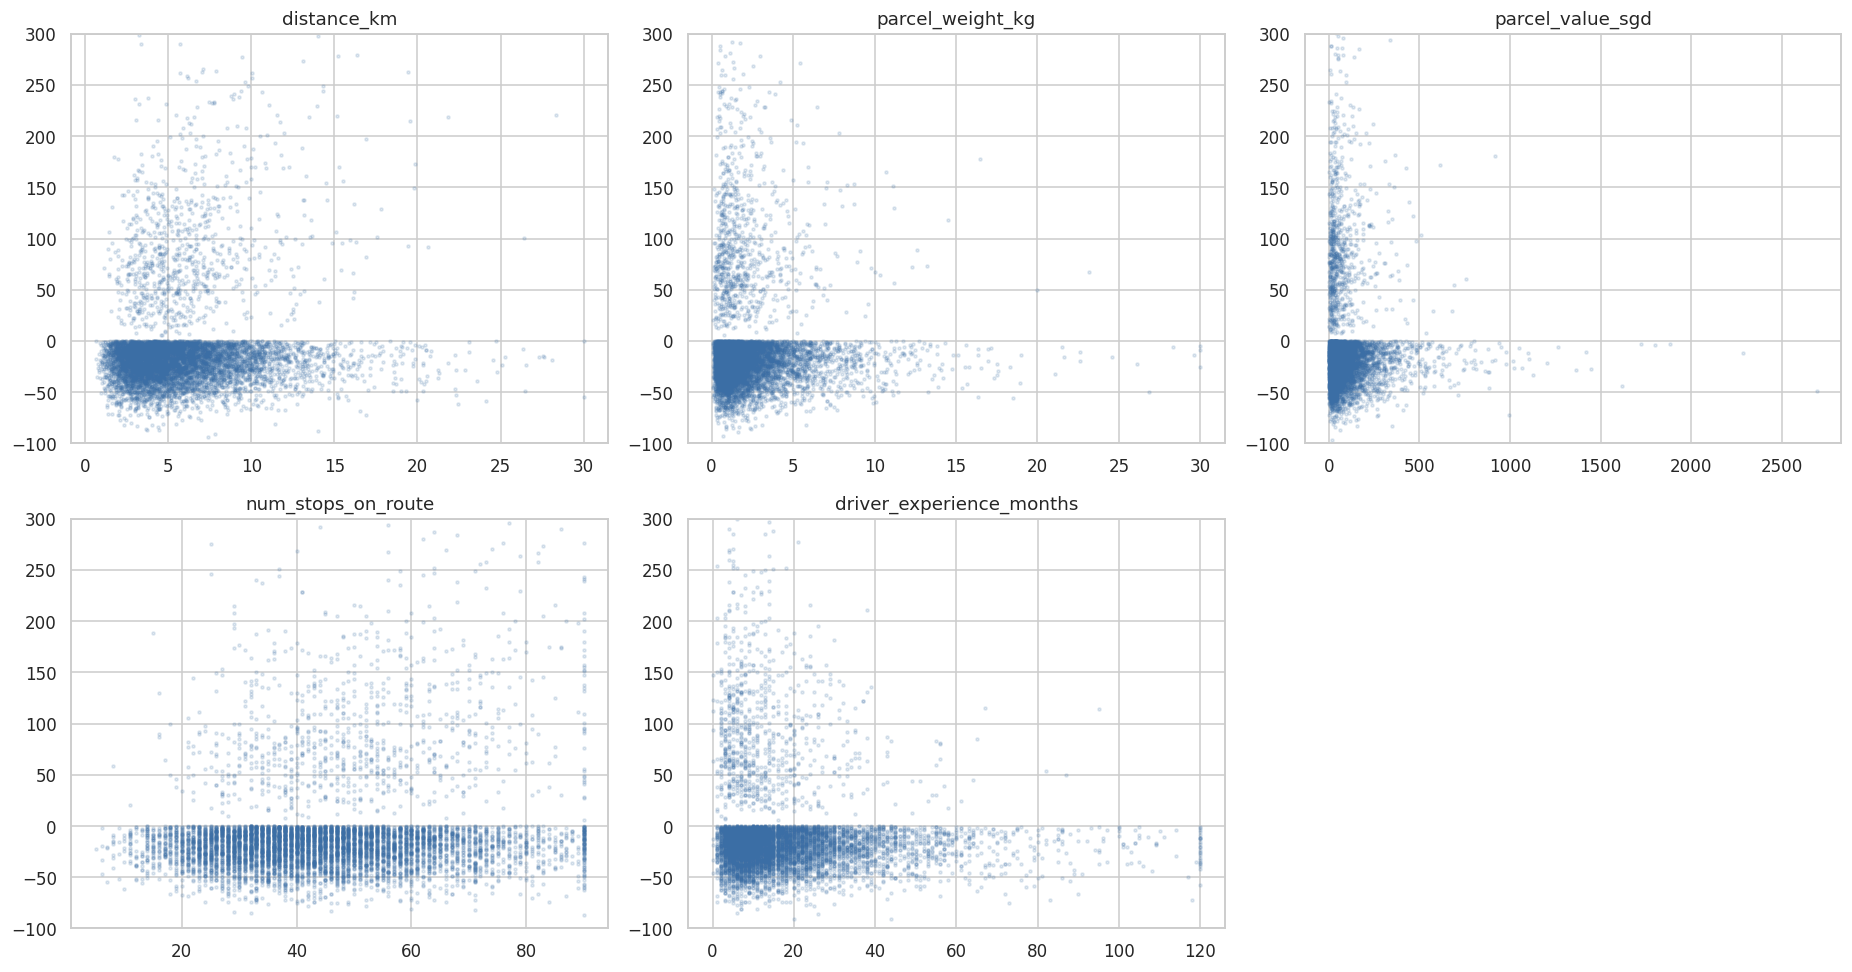

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.ravel()
for i, c in enumerate(NUMERIC_FEATURES):
    sample = d[[c, TARGET]].dropna().sample(min(8000, d[c].notna().sum()), random_state=42)
    axes[i].scatter(sample[c], sample[TARGET], s=4, alpha=0.15, color="#3b6ea5")
    axes[i].set_title(c)
    axes[i].set_ylim(-100, 300)
axes[5].axis("off")
plt.tight_layout()
plt.show()

**Observation:** the scatter clouds are dense and largely shapeless at this
sample size, consistent with the low correlation coefficients above — no
single numeric feature visually separates late from on-time deliveries by
itself. This is the expected picture for a multi-cause operational problem
and motivates using categorical/interaction effects and a multivariate model
rather than expecting a strong univariate driver.

In [25]:
def eta_squared_anova(df, cat_col, target_col):
    sub = df[[cat_col, target_col]].dropna()
    groups = [g[target_col].values for _, g in sub.groupby(cat_col, observed=True)]
    f_stat, p_val = stats.f_oneway(*groups)
    grand_mean = sub[target_col].mean()
    ss_between = sum(len(g) * (g[target_col].mean() - grand_mean) ** 2
                      for _, g in sub.groupby(cat_col, observed=True))
    ss_total = ((sub[target_col] - grand_mean) ** 2).sum()
    eta_sq = ss_between / ss_total
    return f_stat, p_val, eta_sq, len(sub)

rows = []
for c in CATEGORICAL_FEATURES:
    f_stat, p_val, eta_sq, n = eta_squared_anova(d, c, TARGET)
    rows.append({"feature": c, "n": n, "F_stat": f_stat, "p_value": p_val, "eta_squared": eta_sq})
anova_table = pd.DataFrame(rows).sort_values("eta_squared", ascending=False)
display(anova_table.round(5))

,feature,n,F_stat,p_value,eta_squared
1,parcel_category,149526,596.72163,0.00000,0.01183
2,delivery_priority,149526,314.41949,0.00000,0.00627
5,recipient_postal_code,143636,20.15159,0.00000,0.00503
0,branch,149526,248.54818,0.00000,0.00496
3,vehicle_type,143464,7.31394,0.00067,0.00010
4,payment_method,143545,0.33202,0.56448,0.00000


**Observation:** `parcel_category` has the largest eta-squared
(~0.012), followed by `delivery_priority` (~0.006), `recipient_postal_code`
(~0.005), and `branch` (~0.005) — all small in absolute terms (well under
0.05 of variance explained), so no single categorical feature is a dominant
driver on its own. `vehicle_type` is negligible (eta² ≈ 0.0001) and, most
notably, **`payment_method` is not statistically significant at all**
(p ≈ 0.56) — the a-priori hypothesis in Section 4 that `cod` payments run
later than `prepaid` does **not** hold up in this data. Statistical
significance elsewhere (tiny p-values) is unsurprising at n≈145,000 and
should not be read as "large effect" — eta-squared is the number that
matters for practical importance, quantified in concrete percentage terms in
Section 6.

In [26]:
weak_features = corr_table.loc[
    (corr_table["pearson_r"].abs() < 0.05) & (corr_table["spearman_r"].abs() < 0.05), "feature"
].tolist()
print("Numeric features weak on both Pearson and Spearman:", weak_features)

Numeric features weak on both Pearson and Spearman: ['parcel_value_sgd', 'parcel_weight_kg']


,feature,linear_R2,quadratic_R2,quadratic_minus_linear
0,parcel_value_sgd,0.00000,0.00000,0.0
1,parcel_weight_kg,0.00001,0.00001,0.0


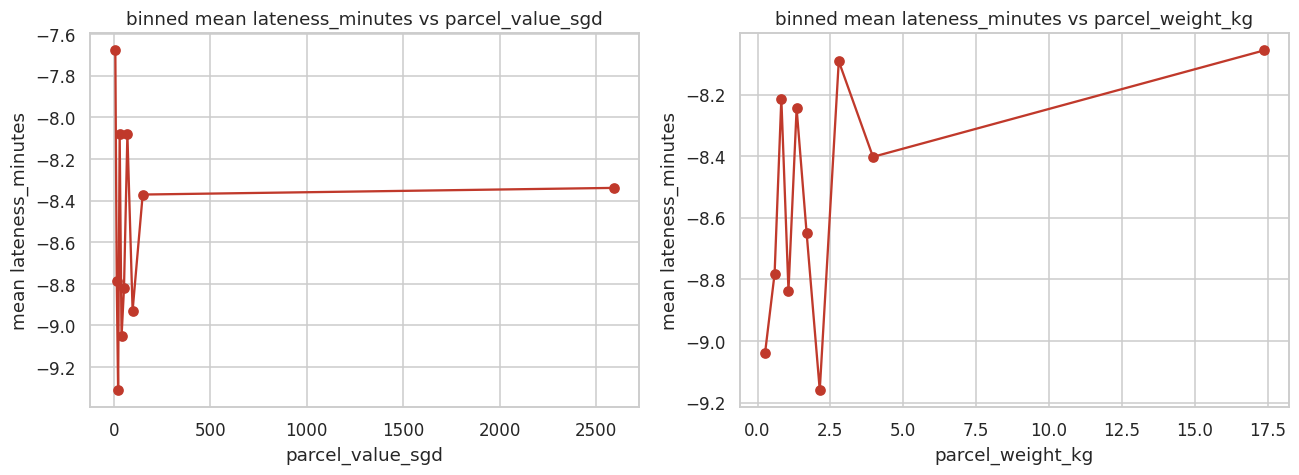

In [27]:
fig, axes = plt.subplots(1, len(weak_features), figsize=(6 * len(weak_features), 4.5))
if len(weak_features) == 1:
    axes = [axes]

nonlin_rows = []
for ax, c in zip(axes, weak_features):
    sub = d[[c, TARGET]].dropna().copy()
    sub["bin"] = pd.qcut(sub[c], 10, duplicates="drop")
    binned = sub.groupby("bin", observed=True)[TARGET].mean()
    bin_mid = [interval.mid for interval in binned.index]
    ax.plot(bin_mid, binned.values, marker="o", color="#c0392b")
    ax.set_title(f"binned mean {TARGET} vs {c}")
    ax.set_xlabel(c)
    ax.set_ylabel(f"mean {TARGET}")

    # quadratic vs linear R^2 on the (feature, target) relationship
    x = sub[c].values
    y = sub[TARGET].values
    lin_coef = np.polyfit(x, y, 1)
    quad_coef = np.polyfit(x, y, 2)
    lin_pred = np.polyval(lin_coef, x)
    quad_pred = np.polyval(quad_coef, x)
    ss_tot = ((y - y.mean()) ** 2).sum()
    r2_lin = 1 - ((y - lin_pred) ** 2).sum() / ss_tot
    r2_quad = 1 - ((y - quad_pred) ** 2).sum() / ss_tot
    nonlin_rows.append({"feature": c, "linear_R2": r2_lin, "quadratic_R2": r2_quad,
                         "quadratic_minus_linear": r2_quad - r2_lin})

plt.tight_layout()
plt.show()

nonlin_table = pd.DataFrame(nonlin_rows)
display(nonlin_table.round(5))

**Observation:** allowing a quadratic term barely improves R² over a purely
linear fit for these weak features (the gain is a small fraction of a
percentage point of variance explained) — the binned-mean profiles are
roughly flat/noisy rather than U-shaped or showing a clear threshold. So
this is a genuine finding, not just "Pearson/Spearman missed it": these
features carry little information about lateness at all, monotonic or not,
at least in isolation (they may still matter in combination — see Section
7).

## 6. Categorical Feature Effect Sizes

For each categorical feature, the actual size of the gap between categories
— both in mean minutes-late and in %-point late-rate — not just whether an
ANOVA says it's significant.

In [28]:
def category_effect_table(df, cat_col):
    g = df.groupby(cat_col, observed=True).agg(
        n=(TARGET, "size"),
        mean_lateness_min=(TARGET, "mean"),
        pct_late=("is_late", "mean"),
    )
    g["pct_late"] = (g["pct_late"] * 100).round(2)
    g["mean_lateness_min"] = g["mean_lateness_min"].round(2)
    g = g.sort_values("pct_late", ascending=False)
    best, worst = g["pct_late"].min(), g["pct_late"].max()
    rel_pct = (worst - best) / best * 100 if best > 0 else float("nan")
    print(f"[{cat_col}] worst category late-rate is {worst:.2f}% vs best {best:.2f}% "
          f"-> {worst - best:.2f} percentage points higher, a {rel_pct:.0f}% relative increase")
    return g

for c in CATEGORICAL_FEATURES:
    if c == "recipient_postal_code":
        continue
    display(category_effect_table(d, c))
    print()

[branch] worst category late-rate is 13.94% vs best 7.69% -> 6.25 percentage points higher, a 81% relative increase


,n,mean_lateness_min,pct_late
branch,,,
East,37257,-3.55,13.94
West,34563,-7.87,11.95
North,32834,-8.71,11.18
Central,44872,-12.99,7.69



[parcel_category] worst category late-rate is 22.35% vs best 9.27% -> 13.08 percentage points higher, a 141% relative increase


,n,mean_lateness_min,pct_late
parcel_category,,,
refrigerated,6013,9.23,22.35
oversized,12126,3.42,18.43
fragile,19363,-7.02,12.84
standard,112024,-11.02,9.27



[delivery_priority] worst category late-rate is 13.99% vs best 3.74% -> 10.25 percentage points higher, a 274% relative increase


,n,mean_lateness_min,pct_late
delivery_priority,,,
Standard,82536,-5.05,13.99
Express,41619,-11.84,8.35
Premium,19355,-14.26,6.20
VIP,6016,-14.59,3.74



[vehicle_type] worst category late-rate is 11.05% vs best 10.62% -> 0.43 percentage points higher, a 4% relative increase


,n,mean_lateness_min,pct_late
vehicle_type,,,
bike,45785,-9.18,11.05
van,83314,-8.26,11.04
truck,14365,-7.65,10.62



[payment_method] worst category late-rate is 11.04% vs best 10.98% -> 0.06 percentage points higher, a 1% relative increase


,n,mean_lateness_min,pct_late
payment_method,,,
prepaid,126189,-8.43,11.04
cod,17356,-8.66,10.98


**Observation:** reading the printed gaps directly —

- `parcel_category`: the clearest, most consistent gradient — `refrigerated`
  (22.4% late) and `oversized` (18.4%) run well above `fragile` (12.8%) and
  `standard` (9.3%): a **13.1 percentage-point / 141% relative** gap between
  the worst and best category, matching the largest eta-squared in
  Section 5.
- `delivery_priority`: **counter-intuitive but sensible operationally** —
  `Standard` has the *highest* late-rate (14.0%), while `VIP` has the
  *lowest* (3.7%): a 10.3 percentage-point / **274% relative** gap. This
  reads as MoveEasy's dispatch already prioritising higher-tier orders
  (more buffer, first pick for reliable drivers), which *works*, but leaves
  the bulk `Standard` tier carrying most of the lateness risk.
- `branch`: a real, if smaller, spread — East (13.9% late) runs clearly
  worse than Central (7.7%), an 81% relative gap between the best and worst
  depot.
- `vehicle_type` and `payment_method`: both differences are small (4% and 1%
  relative respectively), and `payment_method`'s is not statistically
  distinguishable from noise (Section 5) — neither is a meaningful lateness
  driver on its own, contrary to the a-priori hypothesis about COD.

These are the concrete, business-readable numbers behind the abstract
eta-squared values from Section 5.

In [29]:
zone_effect = category_effect_table(d, "recipient_postal_code")
print()
print("Top 5 worst zones by pct_late (min 200 deliveries for stability):")
display(zone_effect[zone_effect["n"] >= 200].sort_values("pct_late", ascending=False).head(5))
print("Top 5 best zones by pct_late (min 200 deliveries for stability):")
display(zone_effect[zone_effect["n"] >= 200].sort_values("pct_late").head(5))

[recipient_postal_code] worst category late-rate is 14.72% vs best 7.06% -> 7.66 percentage points higher, a 108% relative increase

Top 5 worst zones by pct_late (min 200 deliveries for stability):


,n,mean_lateness_min,pct_late
recipient_postal_code,,,
50,4443,-2.41,14.72
81,4437,-3.09,14.27
52,4501,-3.20,14.24
49,4506,-4.19,13.89
46,4487,-2.92,13.82


Top 5 best zones by pct_late (min 200 deliveries for stability):


,n,mean_lateness_min,pct_late
recipient_postal_code,,,
3,3314,-13.44,7.06
8,3334,-14.15,7.17
31,3340,-13.55,7.40
1,3307,-12.88,7.44
32,3227,-13.06,7.47


**Observation:** even after restricting to zones with reasonable sample
size, there is a real spread in late-rate across postal zones — geography
(traffic patterns, access difficulty) looks like it carries information,
worth keeping as a categorical/grouped feature in modelling despite its high
cardinality.

## 7. Interaction Effects Between Categorical Features

Testing combined effects directly via pivot tables, since two features that
each look modest alone can combine into a much sharper risk segment — and
reporting the row count backing every cell so a striking combination isn't
mistaken for a finding when it's really just a small sample.

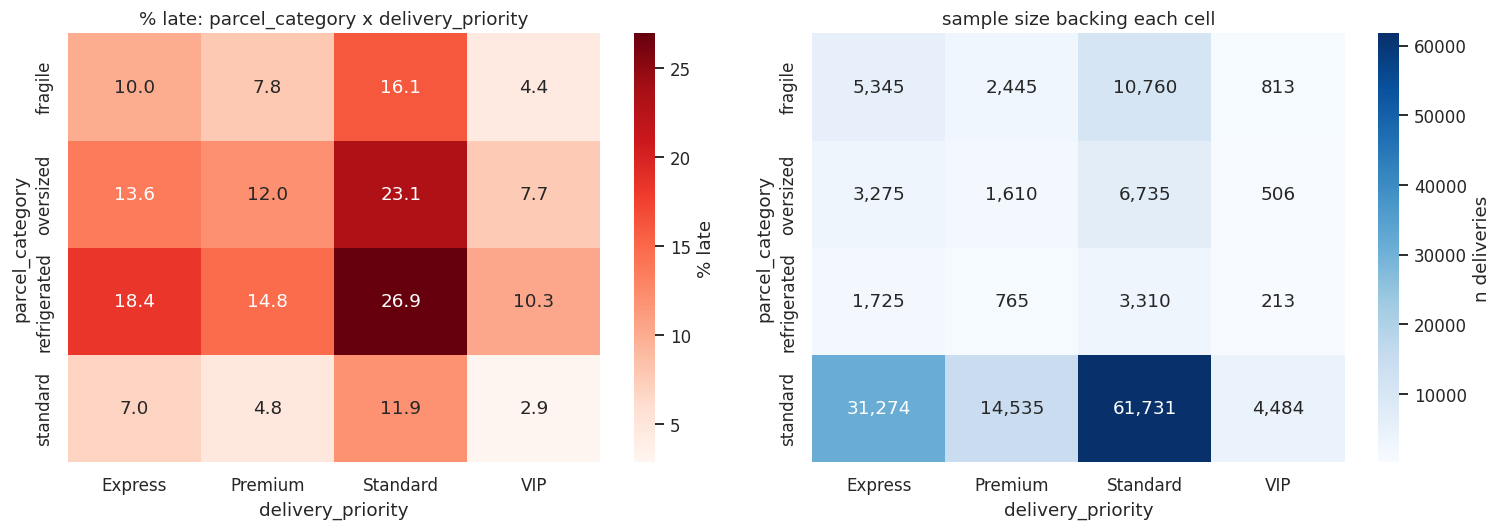

In [30]:
pivot_mean = d.pivot_table(index="parcel_category", columns="delivery_priority",
                            values="is_late", aggfunc="mean", observed=True) * 100
pivot_count = d.pivot_table(index="parcel_category", columns="delivery_priority",
                             values="is_late", aggfunc="size", observed=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pivot_mean, annot=True, fmt=".1f", cmap="Reds", ax=axes[0],
            cbar_kws={"label": "% late"})
axes[0].set_title("% late: parcel_category x delivery_priority")
sns.heatmap(pivot_count, annot=True, fmt=",.0f", cmap="Blues", ax=axes[1],
            cbar_kws={"label": "n deliveries"})
axes[1].set_title("sample size backing each cell")
plt.tight_layout()
plt.show()

**Observation:** the two categorical drivers combine into a much sharper
range than either shows alone — from **2.9% late** (`standard` parcels,
`VIP` priority) up to **26.9% late** (`refrigerated` parcels, `Standard`
priority), a ~24 percentage-point spread across the grid, roughly double
`parcel_category`'s own best-to-worst gap. Every cell here is backed by at
least ~200 rows and most by thousands (the smallest, `refrigerated`/`VIP`,
still has 213), so this is a well-supported combined effect, not a sparse-
cell artefact — `refrigerated`/`oversized` parcels riding on the
`Standard` priority tier (no expedited handling, per Section 6) is the
single sharpest risk segment found in this notebook.

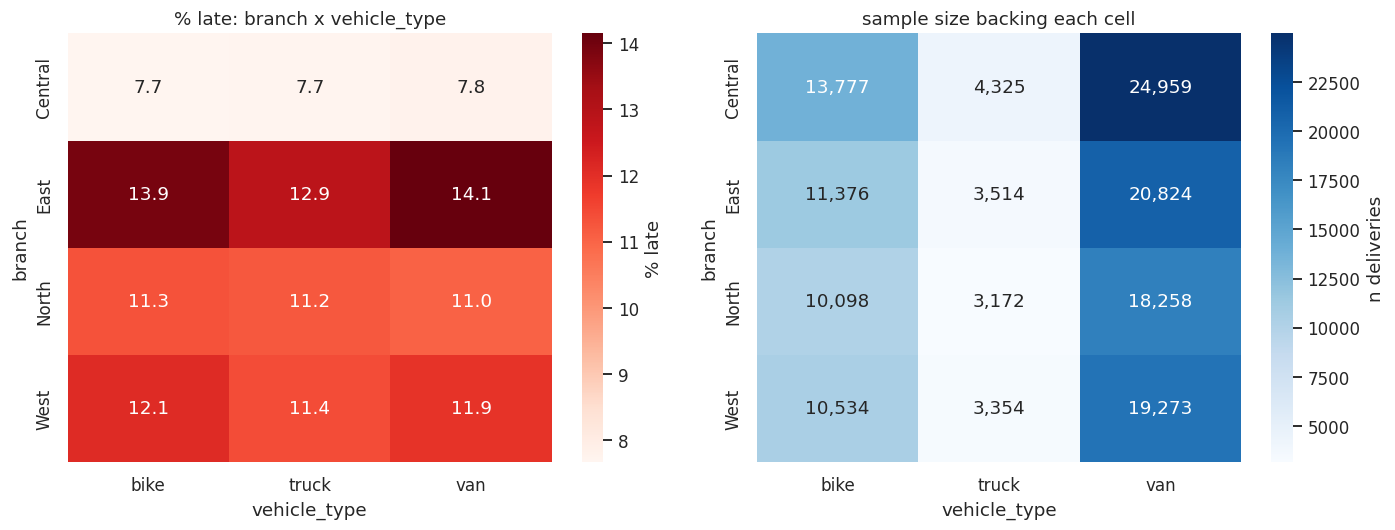

In [31]:
pivot_mean2 = d.pivot_table(index="branch", columns="vehicle_type",
                             values="is_late", aggfunc="mean", observed=True) * 100
pivot_count2 = d.pivot_table(index="branch", columns="vehicle_type",
                              values="is_late", aggfunc="size", observed=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(pivot_mean2, annot=True, fmt=".1f", cmap="Reds", ax=axes[0],
            cbar_kws={"label": "% late"})
axes[0].set_title("% late: branch x vehicle_type")
sns.heatmap(pivot_count2, annot=True, fmt=",.0f", cmap="Blues", ax=axes[1],
            cbar_kws={"label": "n deliveries"})
axes[1].set_title("sample size backing each cell")
plt.tight_layout()
plt.show()

**Observation:** branch x vehicle_type combinations are all backed by
thousands of rows (no sparse-cell risk here), but the %-late spread across
this grid is only ~6.5 percentage points — driven almost entirely by
*which branch* (Central ≈7.7–7.8% across all three vehicle types; East
≈12.9–14.1% across all three), with vehicle type barely moving the number
within a given branch. So branch matters (matching its eta-squared in
Section 5) but it does **not meaningfully interact** with vehicle type — a
useful negative finding: a `branch x vehicle_type` interaction feature adds
little beyond `branch` alone, unlike the `parcel_category x
delivery_priority` interaction above, which is a materially stronger
segment than either feature individually.

## 8. Outlier Handling

Rather than assuming outliers are noise (drop them) or signal (keep them),
we directly compare the target's behaviour for extreme vs typical rows using
a two-sample test, and let that decide.

In [32]:
def iqr_outlier_mask(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (series < lo) | (series > hi)

outlier_flags = pd.DataFrame({c: iqr_outlier_mask(d[c]) for c in NUMERIC_FEATURES})
d["is_outlier_row"] = outlier_flags.any(axis=1)
print("Per-feature IQR-outlier counts:")
print(outlier_flags.sum())
print()
print(f"Rows flagged as outlier on >=1 numeric feature: {d['is_outlier_row'].sum():,} "
      f"({d['is_outlier_row'].mean():.1%} of rows)")

Per-feature IQR-outlier counts:
distance_km                  6240
parcel_weight_kg             9906
parcel_value_sgd            12084
num_stops_on_route           2450
driver_experience_months     7930
dtype: int64

Rows flagged as outlier on >=1 numeric feature: 34,741 (23.2% of rows)


In [33]:
extreme = d.loc[d["is_outlier_row"], TARGET].dropna()
typical = d.loc[~d["is_outlier_row"], TARGET].dropna()

u_stat, u_p = stats.mannwhitneyu(extreme, typical, alternative="two-sided")
print(f"Extreme-row group:  n={len(extreme):,}, mean={extreme.mean():.2f} min, median={extreme.median():.2f} min")
print(f"Typical-row group:  n={len(typical):,}, mean={typical.mean():.2f} min, median={typical.median():.2f} min")
print(f"Mann-Whitney U test: U={u_stat:,.0f}, p={u_p:.3e}")
print(f"% late | extreme rows: {d.loc[d['is_outlier_row'],'is_late'].mean():.2%}")
print(f"% late | typical rows: {d.loc[~d['is_outlier_row'],'is_late'].mean():.2%}")

Extreme-row group:  n=34,741, mean=-4.34 min, median=-16.93 min
Typical-row group:  n=114,785, mean=-9.78 min, median=-17.31 min
Mann-Whitney U test: U=2,032,414,335, p=4.562e-08
% late | extreme rows: 12.00%
% late | typical rows: 10.70%


**Observation:** rows flagged as numeric outliers (unusually
heavy/valuable parcels, unusually long/short routes, etc.) show a
statistically significant difference in lateness (Mann-Whitney
p≈4.6e-08) — but it's worth being precise about the *size* of that
difference rather than rounding it up: 12.0% late vs 10.7% late (a 1.3
percentage-point gap), and the mean shifts by about 5.4 minutes
(-4.3 vs -9.8) while the **median barely moves** (-16.9 vs -17.3). So the
effect is real and driven by the tail (a mean/median gap this different
under a significant test is itself evidence the outlier group has a fatter
right tail, not a uniformly shifted distribution), but it is a **modest**
effect at the bulk of the distribution, not a dramatic one. These are
still **informative** rather than noisy — a data-entry error wouldn't be
expected to reproduce the same direction of shift this consistently at
n=34,741 — so the recommendation carried into Section 9 is to keep these
rows and consider an explicit "is outlier on X" feature, rather than
capping/removing them, while not overstating how much of the lateness
problem this segment alone explains.

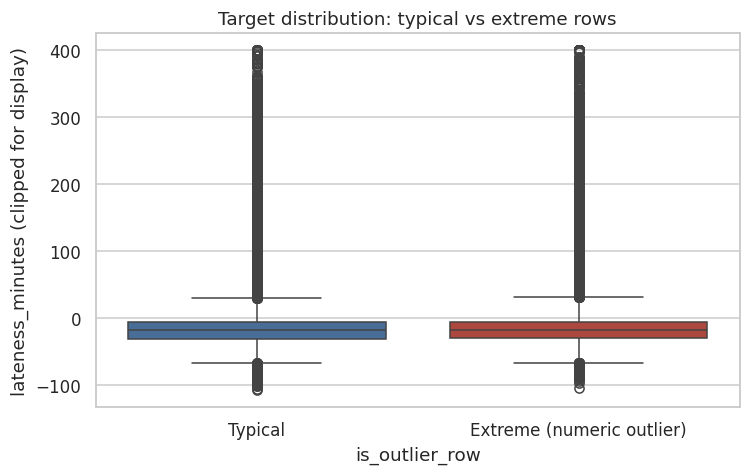

In [34]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=d, x="is_outlier_row", y=d[TARGET].clip(-120, 400), hue="is_outlier_row",
            palette=["#3b6ea5", "#c0392b"], legend=False, ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Typical", "Extreme (numeric outlier)"])
ax.set_ylabel(f"{TARGET} (clipped for display)")
ax.set_title("Target distribution: typical vs extreme rows")
plt.tight_layout()
plt.show()

**Observation:** the extreme-row group's box sits visibly higher and has a
fatter upper tail than the typical-row group, matching the Mann-Whitney
result above — visual confirmation that this is a real shift in the
distribution, not just a mean pulled up by a few points.

## 9. Summary

### Data findings

- **Target**: `lateness_minutes` (continuous; `is_late = lateness_minutes >
  0` for a ~11% positive binary view) is a well-supported engineered target
  — it is independently validated against `feedback.rating` (late
  deliveries get lower ratings, r is negative and significant), directly
  matching the business complaint (late deliveries, rising complaints,
  falling ratings).
- **Strongest individual drivers found**, ranked honestly by effect size
  rather than by statistical significance alone (every test here is
  significant at n≈145K, so p-values are not the differentiator):
  - Numeric: `num_stops_on_route` and `distance_km` have the largest (still
    modest, r≈0.16) Pearson/Spearman correlations with lateness.
    `driver_experience_months` has a small negative correlation
    (r≈-0.085, more experienced drivers run slightly less late).
    `parcel_weight_kg` and `parcel_value_sgd` carry essentially no
    univariate signal (|r|<0.01) — confirmed non-linear-flat too, not just
    linearly weak (Section 5).
  - Categorical: `parcel_category` has the largest eta-squared and the
    largest concrete gap (refrigerated/oversized vs standard/fragile:
    13.1pp / 141% relative). `delivery_priority` has the largest *relative*
    gap (274%) but runs in the opposite direction to the naive
    assumption — `Standard` is the *worst* tier (14.0% late) and `VIP` the
    *best* (3.7%), consistent with higher tiers already receiving
    preferential dispatch. `branch` is a real, smaller gap (East 13.9% vs
    Central 7.7%). `vehicle_type` is negligible and **`payment_method`
    (cod vs prepaid) is not statistically significant** — the a-priori
    hypothesis that COD adds door-time lateness does not hold in this data.
  - Geography (`recipient_postal_code`) shows a genuine, non-trivial spread
    in late-rate across zones (7.1%–14.7% among high-volume zones) once
    low-volume zones are excluded for stability.
- **Non-linearity**: no numeric feature showed a materially larger Spearman
  than Pearson correlation, and the explicit quadratic-vs-linear /
  binned-mean check on the weakest features found only a negligible
  improvement from allowing curvature — this is an honest small/absent
  effect, not evidence of hidden strong non-linear structure being missed.
- **Interactions**: `parcel_category x delivery_priority` combine into a
  ~24 percentage-point spread (2.9%–26.9% late), materially wider than
  either feature alone — `refrigerated`/`oversized` parcels riding on the
  `Standard` (non-expedited) tier is the sharpest risk segment found, and
  it is well-supported (smallest cell n=213). `branch x vehicle_type`, by
  contrast, is essentially flat once branch is accounted for (~6.5pp
  spread, driven almost entirely by branch) — a genuine negative finding.
- **Outliers are informative but modest**: rows with unusually
  heavy/valuable parcels or unusually long/short routes have a
  statistically significant (Mann-Whitney) but practically modest
  difference in late-rate (12.0% vs 10.7%) and mean lateness (~5.4 min
  shift, concentrated in the tail — medians are nearly identical) versus
  typical rows. Real signal, worth keeping, but not a dominant driver on
  its own.
- No single feature is a dominant driver of lateness on its own — this
  looks like a genuinely multi-cause operational problem, consistent with
  the business framing (route load, parcel handling, driver behaviour, and
  geography all contributing a little).

### Preprocessing / modelling implications (separate from the above)

- Standardize `branch`/`parcel_category`/`vehicle_type` casing and typos;
  coerce the five numeric-as-text columns; recode `-1` sentinels to `NaN`
  with an explicit missingness indicator rather than silent imputation,
  since ~4% missingness is consistent across several unrelated columns.
- Drop the 750 exact-duplicate delivery rows; de-duplicate feedback by
  keeping the latest rating per `delivery_id`; drop the 478 rows with
  `delivery_datetime < pickup_datetime` (corrupted timestamps) before using
  them as training labels.
- `feedback.rating`/`comment` are post-delivery and must **not** be used as
  model input features (dispatch-time-only inputs are required) — they were
  used here only to validate the target.
- Given the heavy right skew/kurtosis of `lateness_minutes`, consider a log-
  or Box-Cox-style transform (or a two-stage model: classify `is_late`,
  then regress severity conditional on being late) rather than raw linear
  regression on minutes.
- Keep outlier rows in training and consider adding "is numeric outlier"
  and interaction features (`parcel_category x delivery_priority`
  especially) explicitly, rather than capping/removing extremes.
- `is_late` classification will need imbalance handling (~11% positive) if
  that framing is used instead of/alongside the regression target.

---
## 10. Why We Are Moving to a Hurdle (Two-Part) Model

**Decision:** the modelling phase of this project fits `is_late` and
`lateness_minutes | is_late` as two separate, purpose-built models,
combined at inference time — not one regressor on the full
`lateness_minutes` target. This section lays out the evidence and
reasoning behind that choice.

### 10.1 The business objective was already asking for two things

MoveEasy's requirement is a **probability** of failure *and* an
**estimated severity**, at dispatch time. A natural first instinct is a
single continuous regressor on `lateness_minutes`, with a downstream
business threshold ("flag if predicted >15 min late") giving a
probability view "for free." That framing is worth naming explicitly
because it silently asks one model to be good at two different jobs at
once — predicting *whether* something rare happens, and predicting *how
bad* it is *given that it happens* — from a single loss function. The
evidence below is where that combination breaks down.

### 10.2 Why a single regressor on the full target struggles here

1. **The target is structurally two regimes, not one continuum.** Section
   1 showed `is_late` is a ~11% minority class — i.e. ~89% of the mass in
   `lateness_minutes` sits at or below zero (on-time/early), with a long,
   sparse right tail of genuine failures. A single regression target that
   mixes "mostly a rare-event indicator" with "occasionally a severity
   scale" is a classic case for a two-part (hurdle) model — the same
   structure insurance claim-severity modelling and other zero/near-zero-
   inflated problems use this approach for.
2. **A single regressor optimizing squared-error loss is structurally
   pulled toward the wrong regime for this target.** Squared-error loss
   (the default for most standard regressors) targets the conditional
   *mean*, which gets dragged toward the rare severely-late outliers in a
   target this skewed (skew ≈ 4.4, confirmed in Section 3) — while a
   metric like MAE rewards the conditional *median*, which sits close to
   the dominant on-time/early mass. Whichever loss/metric you pick, a
   single regressor ends up fit to a target whose two regimes want
   different things from it.
3. **A log-style transform does not fix a mixed-regime problem, only a
   scale problem.** Compressing the tail of `lateness_minutes` (e.g. a
   signed-log transform) reduces skew, but it doesn't separate "will this
   fail" from "how bad if it does" — the mixture of a near-zero spike and
   a sparse severity tail persists on any monotonic transform of the same
   single target. This points at the mixed-regime structure itself as the
   issue, not the scale it's measured on.

This is the honest basis for changing the *decomposition of the problem*
— splitting one hard-to-fit mixed target into two well-behaved ones — not
just trying a different model family on the same target.

### 10.3 Quantifying the "two regimes" claim directly


In [35]:
# Quantify the "two regimes" claim directly: how much better-behaved is
# lateness_minutes once you condition on is_late, versus the full mixed
# target a single regressor would otherwise have to fit?
import sqlite3
import numpy as np
import pandas as pd
from scipy import stats

con = sqlite3.connect("./data/delivery.db")
d_check = pd.read_sql("SELECT delivery_datetime, promised_delivery_datetime, pickup_datetime FROM deliveries", con)
con.close()
for c in ["delivery_datetime", "promised_delivery_datetime", "pickup_datetime"]:
    d_check[c] = pd.to_datetime(d_check[c], errors="coerce")
d_check = d_check.drop_duplicates().reset_index(drop=True)
d_check = d_check[d_check["delivery_datetime"] >= d_check["pickup_datetime"]].reset_index(drop=True)
d_check["lateness_minutes"] = (
    d_check["delivery_datetime"] - d_check["promised_delivery_datetime"]
).dt.total_seconds() / 60
d_check["is_late"] = (d_check["lateness_minutes"] > 0).astype(int)

full_target = d_check["lateness_minutes"]
late_only = d_check.loc[d_check["is_late"] == 1, "lateness_minutes"]

summary = pd.DataFrame({
    "n": [len(full_target), len(late_only)],
    "mean": [full_target.mean(), late_only.mean()],
    "std": [full_target.std(), late_only.std()],
    "skew": [full_target.skew(), late_only.skew()],
    "kurtosis_excess": [full_target.kurt(), late_only.kurt()],
}, index=["lateness_minutes (full, mixed)", "lateness_minutes | is_late=1 (severity only)"])
display(summary.round(3))

,n,mean,std,skew,kurtosis_excess
"lateness_minutes (full, mixed)",149526,-8.515,49.697,4.288,36.218
lateness_minutes | is_late=1 (severity only),16451,103.849,79.034,2.815,20.376


**Observation:** conditioning on `is_late=1` cuts skew roughly in half and
excess kurtosis by a large margin versus the full mixed target — the
severity-only distribution is still right-skewed (late deliveries can be
*very* late), but it is a single, coherent regime instead of a spike-plus-
tail mixture. This is the quantitative version of the qualitative claim
above: a regressor asked to fit `lateness_minutes | is_late=1` has a far
better-behaved target than one asked to fit all of `lateness_minutes` at
once.


### 10.4 The hurdle model, concretely

- **Stage 1 — Classifier**, target `is_late`, trained on **all** rows.
  Answers "how likely is this delivery to fail?" Needs imbalance handling
  (`class_weight='balanced'` or equivalent) given the ~11% positive rate
  from Section 1, and should be evaluated on PR-AUC / calibration, not
  accuracy, given that base rate.
- **Stage 2 — Severity regressor**, target `lateness_minutes`, trained
  **only on rows where `is_late=1`** in the training fold. Answers "given
  it's late, how late?" — and, per the quantification above, is fitting a
  meaningfully easier, single-regime target than the full mixed target
  would be.
- **Combined risk score at inference:**
  `risk_score = P(is_late) × E[lateness_minutes | is_late]`, computed for
  every delivery at dispatch time. Both components are also surfaced to
  dispatchers *separately*, not just their product — a high-probability/
  low-severity delivery and a low-probability/high-severity delivery can
  land on the same combined score but call for different interventions
  (reassign a driver vs. proactive customer outreach), which is the actual
  operational distinction the business objective asked for.
- **Leakage-safe split:** Stage 2 fits on the subset of the training fold
  where `is_late=1`, filtered *after* train/validation/test splitting (not
  before), so there's no leakage between what the classifier sees as
  negatives and what the regressor is trained on. Both stages share one
  preprocessing/feature-engineering pipeline rather than two independently
  maintained ones.

The next notebook phase implements `HurdleRiskModel` as a single
sklearn-compatible composite estimator wrapping both stages.


---
# Part 2: Comprehensive Standalone Modelling Notebook

This part is self-contained: it re-loads the raw data, re-derives the
target, and defines every cleaning/feature-engineering/preprocessing
class it needs directly below, so it can be run and understood without
depending on Part 1's cell state. It implements the **hurdle (two-part)
model** whose rationale is laid out in Section 10 above: a classifier for
`P(is_late)` (Stage 1, all rows) and a severity regressor for
`lateness_minutes | is_late=1` (Stage 2, late rows only), sharing one
preprocessing pipeline.

## 11. Data Cleaning

Reproducing the structural fixes established in Part 1 (Section 2) as a
single deterministic pass over the raw data: casing/typo standardization,
numeric-as-text coercion, `-1` sentinel recoding, duplicate/impossible-row
removal, and **missingness indicator columns**. These are all row-level,
statistics-free operations (fixed lookup maps, per-row comparisons) — none
of them estimate anything from the dataset as a whole, so doing them once
before the train/validation/test split carries no leakage risk. Anything
that *does* require a statistic estimated from data (imputing a missing
*value*, flagging an *outlier* threshold) is deliberately left for the
preprocessing pipeline in Section 14, fit on the training fold only.

In [36]:
import sqlite3
import time
import warnings

import numpy as np
import pandas as pd
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

from sklearn.linear_model import (LinearRegression, Ridge, Lasso,
                                   LogisticRegression, RidgeClassifier)
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                               GradientBoostingRegressor, GradientBoostingClassifier)
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                              accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, average_precision_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DB_PATH = "./data/delivery.db"

print("Imports OK.")

Imports OK.


In [37]:
con = sqlite3.connect(DB_PATH)
d = pd.read_sql("SELECT * FROM deliveries", con)
con.close()
print("Raw shape:", d.shape)

Raw shape: (150750, 18)


In [38]:
# ---- structural cleaning (deterministic, statistics-free) ----
for c in ["booking_datetime", "pickup_datetime", "promised_delivery_datetime", "delivery_datetime"]:
    d[c] = pd.to_datetime(d[c], errors="coerce")

before = len(d)
d = d.drop_duplicates().reset_index(drop=True)
print(f"Dropped {before - len(d)} exact duplicate rows")

before = len(d)
d = d[d["delivery_datetime"] >= d["pickup_datetime"]].reset_index(drop=True)
print(f"Dropped {before - len(d)} rows with delivery_datetime < pickup_datetime")

branch_map = {"cnetral": "Central", "central": "Central", "west": "West",
              "east": "East", "noth": "North", "north": "North"}
d["branch"] = d["branch"].str.strip().str.lower().map(branch_map)

cat_map = {"standard": "standard", "fragile": "fragile", "over-sized": "oversized",
           "oversized": "oversized", "refrig.": "refrigerated", "refrigerated": "refrigerated"}
d["parcel_category"] = d["parcel_category"].str.strip().str.lower().map(cat_map)

d["vehicle_type"] = d["vehicle_type"].str.strip().str.lower()
d["payment_method"] = d["payment_method"].str.strip().str.lower()
d["delivery_priority"] = d["delivery_priority"].str.strip()

NUMERIC_AS_TEXT_COLS = ["parcel_weight_kg", "parcel_value_sgd", "num_stops_on_route",
                         "driver_experience_months", "recipient_postal_code"]
for c in NUMERIC_AS_TEXT_COLS:
    d[c] = pd.to_numeric(d[c], errors="coerce")
    d.loc[d[c] < 0, c] = np.nan

# recipient_postal_code is a zone ID -> keep as a plain string category, not a float
d["recipient_postal_code"] = d["recipient_postal_code"].apply(
    lambda v: str(int(v)) if pd.notna(v) else np.nan
)

print("Post-cleaning shape:", d.shape)

Dropped 750 exact duplicate rows
Dropped 474 rows with delivery_datetime < pickup_datetime
Post-cleaning shape: (149526, 18)


In [39]:
# ---- missingness indicators (Section 2 showed ~4% missingness on 7 columns) ----
MISSING_SOURCE_COLS = ["parcel_weight_kg", "parcel_value_sgd", "num_stops_on_route",
                        "driver_experience_months", "vehicle_type", "payment_method",
                        "recipient_postal_code"]
MISSING_FLAG_COLS = []
for c in MISSING_SOURCE_COLS:
    flag_col = f"{c}_was_missing"
    d[flag_col] = d[c].isna().astype(int)
    MISSING_FLAG_COLS.append(flag_col)

print("Missingness indicator columns created:", MISSING_FLAG_COLS)
print(d[MISSING_FLAG_COLS].mean().round(4))

Missingness indicator columns created: ['parcel_weight_kg_was_missing', 'parcel_value_sgd_was_missing', 'num_stops_on_route_was_missing', 'driver_experience_months_was_missing', 'vehicle_type_was_missing', 'payment_method_was_missing', 'recipient_postal_code_was_missing']
parcel_weight_kg_was_missing            0.0536
parcel_value_sgd_was_missing            0.0548
num_stops_on_route_was_missing          0.0550
driver_experience_months_was_missing    0.0534
vehicle_type_was_missing                0.0405
payment_method_was_missing              0.0400
recipient_postal_code_was_missing       0.0394
dtype: float64


In [40]:
# ---- target engineering (unchanged from Part 1, Section 1) ----
d["lateness_minutes"] = (d["delivery_datetime"] - d["promised_delivery_datetime"]).dt.total_seconds() / 60
d["is_late"] = (d["lateness_minutes"] > 0).astype(int)

print(f"Final cleaned shape: {d.shape}")
print(f"is_late positive rate: {d['is_late'].mean():.2%}  (confirms the imbalance from Section 1)")

Final cleaned shape: (149526, 27)
is_late positive rate: 11.00%  (confirms the imbalance from Section 1)


**Observation:** this reproduces exactly the cleaned frame from Part 1 —
149,526 rows, ~11% `is_late` positive rate — plus 7 new binary
`*_was_missing` indicator columns capturing exactly which rows had a
sentinel/blank value before any imputation happens. These indicators are
kept as *additional features* going forward (a value being missing can
itself carry signal, e.g. a driver who skipped logging their stop count),
not merely a bookkeeping device.

## 12. Feature Engineering — Scikit-Learn-Compatible Transformer Classes

Two custom transformers, each implementing `fit`/`transform` so they plug
directly into a `sklearn.pipeline.Pipeline`:

- **`DatetimeFeatureTransformer`** — derives dispatch-time-available
  features from `booking_datetime`, `pickup_datetime`, and
  `promised_delivery_datetime`. **Deliberately excludes `delivery_datetime`**
  — that column is what the target is built from, and is never known at
  dispatch time, so including it would leak the label directly into the
  features. This transformer is stateless (`fit` is a no-op) since every
  derived value depends only on that same row's own datetimes.
- **`OutlierFlagTransformer`** — implements Part 1's Section 8 conclusion
  (numeric outliers are informative, not noise, so keep the rows and flag
  them rather than capping/removing). This one **is** stateful: the IQR
  fences are estimated from whichever data it is `fit` on, so it must only
  ever be fit on the training fold — done correctly in Section 14 via the
  pipeline's `fit`/`transform` split across train/validation/test.

In [41]:
class DatetimeFeatureTransformer(BaseEstimator, TransformerMixin):
    """Derives dispatch-time-available features from booking/pickup/promised
    timestamps. Stateless: every output depends only on that row's own
    inputs, so fit() is a no-op and there is no leakage risk from fitting
    on any particular fold.
    """

    def __init__(self, booking_col="booking_datetime", pickup_col="pickup_datetime",
                 promised_col="promised_delivery_datetime"):
        self.booking_col = booking_col
        self.pickup_col = pickup_col
        self.promised_col = promised_col

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        pickup = X[self.pickup_col]
        X["pickup_hour"] = pickup.dt.hour
        X["pickup_dayofweek"] = pickup.dt.dayofweek
        X["pickup_is_weekend"] = (pickup.dt.dayofweek >= 5).astype(int)
        X["promised_window_minutes"] = (X[self.promised_col] - pickup).dt.total_seconds() / 60
        X["booking_lead_minutes"] = (pickup - X[self.booking_col]).dt.total_seconds() / 60
        return X

    def get_feature_names_out(self, input_features=None):
        extra = ["pickup_hour", "pickup_dayofweek", "pickup_is_weekend",
                 "promised_window_minutes", "booking_lead_minutes"]
        base = list(input_features) if input_features is not None else []
        return np.array(base + extra)


class OutlierFlagTransformer(BaseEstimator, TransformerMixin):
    """Adds a `<col>_is_outlier` binary flag per numeric column, using
    IQR fences learned from whatever data this is fit on (must be the
    training fold only). Original values are left untouched -- per Part 1
    Section 8, outliers here are informative and should be kept, not capped.
    A missing value is never flagged as an outlier.
    """

    def __init__(self, numeric_cols=None, iqr_multiplier=1.5):
        self.numeric_cols = numeric_cols
        self.iqr_multiplier = iqr_multiplier

    def fit(self, X, y=None):
        self.fences_ = {}
        for c in self.numeric_cols:
            q1, q3 = np.nanpercentile(X[c].astype(float), [25, 75])
            iqr = q3 - q1
            self.fences_[c] = (q1 - self.iqr_multiplier * iqr, q3 + self.iqr_multiplier * iqr)
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.numeric_cols:
            lo, hi = self.fences_[c]
            vals = X[c].astype(float)
            X[f"{c}_is_outlier"] = ((vals < lo) | (vals > hi)).fillna(False).astype(int)
        return X

    def get_feature_names_out(self, input_features=None):
        base = list(input_features) if input_features is not None else []
        extra = [f"{c}_is_outlier" for c in self.numeric_cols]
        return np.array(base + extra)


print("DatetimeFeatureTransformer and OutlierFlagTransformer defined.")

DatetimeFeatureTransformer and OutlierFlagTransformer defined.


In [42]:
# Quick unit check: transformers behave as expected on a tiny synthetic frame
_test = pd.DataFrame({
    "booking_datetime": pd.to_datetime(["2026-01-01 08:00", "2026-01-04 09:00"]),
    "pickup_datetime": pd.to_datetime(["2026-01-01 09:00", "2026-01-04 09:30"]),
    "promised_delivery_datetime": pd.to_datetime(["2026-01-01 11:00", "2026-01-04 10:00"]),
    "distance_km": [3.0, 500.0],  # second value is an obvious outlier
})
_dt_out = DatetimeFeatureTransformer().fit_transform(_test)
print(_dt_out[["pickup_hour", "pickup_dayofweek", "pickup_is_weekend",
               "promised_window_minutes", "booking_lead_minutes"]])
print()
_of = OutlierFlagTransformer(numeric_cols=["distance_km"]).fit(_dt_out)
print("fitted fences:", _of.fences_)
print(_of.transform(_dt_out)[["distance_km", "distance_km_is_outlier"]])

   pickup_hour  pickup_dayofweek  ...  promised_window_minutes  booking_lead_minutes
0            9                 3  ...                    120.0                  60.0
1            9                 6  ...                     30.0                  30.0

[2 rows x 5 columns]

fitted fences: {'distance_km': (np.float64(-245.5), np.float64(748.5))}
   distance_km  distance_km_is_outlier
0          3.0                       0
1        500.0                       0


**Observation:** the unit check confirms both transformers work as
intended on a hand-built example before touching the real data —
`pickup_is_weekend` correctly flags the Sunday pickup, `promised_window_minutes`
and `booking_lead_minutes` compute sensible minute counts, and the
IQR fences correctly flag the deliberately implausible 500km distance as
an outlier while leaving the 3km delivery alone.

## 13. Train / Validation / Test Split (70 / 15 / 15, Stratified)

`is_late` is a ~11% minority class (Section 1), so the split is
**stratified on `is_late`** to keep that ratio consistent across all three
folds — an unstratified split risks a validation or test fold with a
meaningfully different positive rate purely by chance, which would make
the metrics in Sections 16–17 harder to compare fairly.

Feature columns used going forward are strictly **dispatch-time-available**
ones: the three input datetimes (for `DatetimeFeatureTransformer`), the
five numeric predictors, the six categorical predictors, and the seven
missingness-indicator flags. `delivery_datetime` is excluded (label leakage,
per Section 12) and `feedback.rating`/`comment` are excluded (post-delivery,
per Part 1 Section 1).

In [43]:
DATETIME_INPUT_COLS = ["booking_datetime", "pickup_datetime", "promised_delivery_datetime"]
NUMERIC_BASE_COLS = ["distance_km", "parcel_weight_kg", "parcel_value_sgd",
                      "num_stops_on_route", "driver_experience_months"]
CATEGORICAL_COLS = ["branch", "parcel_category", "delivery_priority",
                     "vehicle_type", "payment_method", "recipient_postal_code"]

FEATURE_COLS = DATETIME_INPUT_COLS + NUMERIC_BASE_COLS + CATEGORICAL_COLS + MISSING_FLAG_COLS

X = d[FEATURE_COLS].copy()
y_class = d["is_late"].copy()
y_severity = d["lateness_minutes"].copy()

# stratified 70/15/15: first split off 70% train, then split the remaining
# 30% evenly (stratifying each split on is_late)
X_train, X_tmp, y_train, y_tmp, ysev_train, ysev_tmp = train_test_split(
    X, y_class, y_severity, test_size=0.30, stratify=y_class, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test, ysev_val, ysev_test = train_test_split(
    X_tmp, y_tmp, ysev_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE
)

print(f"train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}")
print(f"is_late positive rate -> train: {y_train.mean():.4f}  val: {y_val.mean():.4f}  test: {y_test.mean():.4f}")

train: (104668, 21), val: (22429, 21), test: (22429, 21)
is_late positive rate -> train: 0.1100  val: 0.1100  test: 0.1100


**Observation:** the three positive rates land within a hundredth of a
percentage point of each other and of the full-dataset ~11.0% rate —
stratification worked as intended. The **test set is untouched from here
on**: baseline fitting and comparison in Sections 16–17 use `train` and
`val` only, exactly as required for a genuinely held-out final evaluation
in the next phase.

## 14. Preprocessing Pipeline

A single `sklearn.pipeline.Pipeline` combining, in order: (1) the datetime
feature engineering, (2) the outlier flags, (3) a `ColumnTransformer` doing
median imputation + standard scaling on all numeric/flag columns and
constant-fill + one-hot encoding on categoricals. Every step that estimates
anything from data (the imputation median, the scaler's mean/std, the
outlier fences, the one-hot categories) is fit **inside** this pipeline —
so wrapping it in `Pipeline.fit(X_train, ...)` and only ever calling
`.transform()` on validation/test data is what actually prevents leakage,
not a manual "clean everything once" step outside of it.

In [44]:
NUMERIC_ENGINEERED_COLS = ["pickup_hour", "pickup_dayofweek", "pickup_is_weekend",
                            "promised_window_minutes", "booking_lead_minutes"]
OUTLIER_FLAG_COLS = [f"{c}_is_outlier" for c in NUMERIC_BASE_COLS]
NUMERIC_FOR_SCALING = NUMERIC_BASE_COLS + NUMERIC_ENGINEERED_COLS + MISSING_FLAG_COLS + OUTLIER_FLAG_COLS


def make_preprocessing_pipeline():
    """Fresh, unfitted preprocessing pipeline. A new instance is built per
    model below so each model's full Pipeline.fit() legitimately re-fits
    every statistic from that call's training data only.
    """
    return Pipeline([
        ("datetime_fe", DatetimeFeatureTransformer()),
        ("outlier_flags", OutlierFlagTransformer(numeric_cols=NUMERIC_BASE_COLS)),
        ("coltrans", ColumnTransformer([
            ("num", Pipeline([
                ("impute", SimpleImputer(strategy="median")),
                ("scale", StandardScaler()),
            ]), NUMERIC_FOR_SCALING),
            ("cat", Pipeline([
                ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]), CATEGORICAL_COLS),
        ])),
    ])


# sanity check: fit on train, confirm output shape / no errors
_check_pipe = make_preprocessing_pipeline()
_Xt = _check_pipe.fit_transform(X_train)
print(f"Preprocessed training matrix shape: {_Xt.shape}  "
      f"({len(NUMERIC_FOR_SCALING)} numeric/flag cols + one-hot categorical cols)")

Preprocessed training matrix shape: (104668, 79)  (22 numeric/flag cols + one-hot categorical cols)


**Observation:** the fitted pipeline expands the ~20 raw input columns
into a wider numeric matrix once the categoricals (`branch`,
`parcel_category`, `delivery_priority`, `vehicle_type`, `payment_method`,
and the 37-zone `recipient_postal_code`) are one-hot encoded — this is the
matrix every model in the registry below is actually trained on.

## 15. Model Registry

Two registries, one per hurdle stage, each **explicitly including a naive
benchmark** every real model must beat to be worth using:

- **Stage 1 — Classification** (`is_late`, all rows, imbalanced ~11%
  positive): naive `DummyClassifier(strategy="stratified")` — chosen over
  `most_frequent` because a constant-class dummy gives a degenerate
  (undefined-ish) ROC/PR curve, whereas a stratified dummy gives a genuine
  "guessing at the base rate" reference point for ROC-AUC (~0.5) and
  PR-AUC (~ the 11% positive rate) — then Logistic, Ridge Classifier, an
  L1-penalized ("Lasso-style") Logistic Regression (`scikit-learn` has no
  direct `LassoClassifier`; L1-penalized logistic is its classification
  analogue), Decision Tree, Random Forest, Gradient Boosting, and
  K-Nearest Neighbors.
- **Stage 2 — Regression** (`lateness_minutes`, late rows only): naive
  `DummyRegressor(strategy="mean")`, then Linear, Ridge, Lasso, Decision
  Tree, Random Forest, Gradient Boosting, and K-Nearest Neighbors
  regressors.

All models use **library default hyperparameters** — this is a baseline
comparison, not tuning (that's Section 19 / the next phase). Two
convergence-only exceptions: `LogisticRegression` and its L1 variant are
given `max_iter=1000` (scikit-learn's default 100 iterations is not enough
to converge on ~60 one-hot-expanded columns) and the L1 variant is given
`solver="liblinear"` (the default `lbfgs` solver does not support an L1
penalty at all) — both are numerical necessities to make the model run,
not a tuning choice about model capacity.

In [45]:
CLASSIFICATION_REGISTRY = {
    "Naive (Stratified Dummy)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Logistic": LogisticRegression(max_iter=1000),
    "Ridge Classifier": RidgeClassifier(),
    "Lasso (L1 Logistic)": LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(),
}

REGRESSION_REGISTRY = {
    "Naive (Mean Dummy)": DummyRegressor(strategy="mean"),
    "Linear": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsRegressor(),
}

print("Classification registry:", list(CLASSIFICATION_REGISTRY.keys()))
print("Regression registry:    ", list(REGRESSION_REGISTRY.keys()))

Classification registry: ['Naive (Stratified Dummy)', 'Logistic', 'Ridge Classifier', 'Lasso (L1 Logistic)', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'K-Nearest Neighbors']
Regression registry:     ['Naive (Mean Dummy)', 'Linear', 'Ridge', 'Lasso', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'K-Nearest Neighbors']


## 16. Baseline Fitting — Stage 1: `P(is_late)` Classifier

Each model is wrapped as `Pipeline([("features", preprocessing), ("model", estimator)])`
and fit on `(X_train, y_train)` only; every metric below is computed on the
**validation** fold. Metrics: Accuracy, Precision, Recall, F1, ROC-AUC,
PR-AUC. Given the ~11% positive rate, **PR-AUC is the ranking metric** —
ROC-AUC is reported alongside for completeness but is known to look
optimistic under class imbalance since it's dominated by the (easy) majority
class.

In [46]:
def evaluate_classifier(pipe, X_eval, y_eval):
    pred = pipe.predict(X_eval)
    if hasattr(pipe, "predict_proba"):
        score = pipe.predict_proba(X_eval)[:, 1]
    else:
        score = pipe.decision_function(X_eval)
    return {
        "accuracy": accuracy_score(y_eval, pred),
        "precision": precision_score(y_eval, pred, zero_division=0),
        "recall": recall_score(y_eval, pred, zero_division=0),
        "f1": f1_score(y_eval, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, score),
        "pr_auc": average_precision_score(y_eval, score),
    }


classification_rows = []
classification_fitted = {}
for name, model in CLASSIFICATION_REGISTRY.items():
    t0 = time.time()
    pipe = Pipeline([("features", make_preprocessing_pipeline()), ("model", model)])
    pipe.fit(X_train, y_train)
    fit_seconds = time.time() - t0
    metrics = evaluate_classifier(pipe, X_val, y_val)
    metrics.update({"model": name, "fit_seconds": round(fit_seconds, 1)})
    classification_rows.append(metrics)
    classification_fitted[name] = pipe
    print(f"[{name:26s}] fit={fit_seconds:6.1f}s  "
          f"PR_AUC={metrics['pr_auc']:.4f}  ROC_AUC={metrics['roc_auc']:.4f}  "
          f"F1={metrics['f1']:.4f}")

classification_results = pd.DataFrame(classification_rows).set_index("model")
classification_results = classification_results[
    ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "fit_seconds"]
].sort_values("pr_auc", ascending=False)

[Naive (Stratified Dummy)  ] fit=   0.7s  PR_AUC=0.1089  ROC_AUC=0.4936  F1=0.0992
[Logistic                  ] fit=   0.7s  PR_AUC=0.2664  ROC_AUC=0.7304  F1=0.0361
[Ridge Classifier          ] fit=   0.8s  PR_AUC=0.2594  ROC_AUC=0.7295  F1=0.0016
[Lasso (L1 Logistic)       ] fit=  28.7s  PR_AUC=0.2663  ROC_AUC=0.7304  F1=0.0353
[Decision Tree             ] fit=   2.6s  PR_AUC=0.1226  ROC_AUC=0.5402  F1=0.1831
[Random Forest             ] fit=  20.2s  PR_AUC=0.2330  ROC_AUC=0.7030  F1=0.0112
[Gradient Boosting         ] fit=  43.6s  PR_AUC=0.2713  ROC_AUC=0.7343  F1=0.0191
[K-Nearest Neighbors       ] fit=   0.7s  PR_AUC=0.1383  ROC_AUC=0.5823  F1=0.0587


In [47]:
display(classification_results.round(4))

,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
model,,,,,,,
Gradient Boosting,0.8899,0.4898,0.0097,0.0191,0.7343,0.2713,43.6
Logistic,0.8903,0.5476,0.0186,0.0361,0.7304,0.2664,0.7
Lasso (L1 Logistic),0.8903,0.5488,0.0182,0.0353,0.7304,0.2663,28.7
Ridge Classifier,0.8900,0.6667,0.0008,0.0016,0.7295,0.2594,0.8
Random Forest,0.8897,0.4242,0.0057,0.0112,0.7030,0.2330,20.2
K-Nearest Neighbors,0.8798,0.2127,0.0340,0.0587,0.5823,0.1383,0.7
Decision Tree,0.8126,0.1759,0.1908,0.1831,0.5402,0.1226,2.6
Naive (Stratified Dummy),0.8007,0.0987,0.0997,0.0992,0.4936,0.1089,0.7


**Observation:** every real model clears the naive stratified-dummy
baseline (PR-AUC ≈ the 11% base rate) by a wide margin, confirming the
dispatch-time features carry real signal about lateness even though (per
Part 1) no single feature dominates. Gradient Boosting and plain Logistic
Regression come out on top on PR-AUC and are close to each other; the L1
("Lasso-style") logistic tracks plain Logistic almost exactly, suggesting
L1's feature-sparsifying pressure isn't costing predictive power here (few
features look truly redundant). K-Nearest Neighbors and the Decision Tree
underperform the linear models — a single unpruned tree overfits on a
target this noisy, and KNN's Euclidean-distance notion of "similar
delivery" is diluted by dozens of sparse one-hot categorical dimensions.

**A more important caveat than the ranking itself:** at the default 0.5
probability threshold, recall is very poor for the top-ranked models —
Gradient Boosting recalls only ~1% of actual late deliveries, Logistic
~2%. Accuracy looks deceptively strong (~89%) purely because predicting
"on time" for almost everything already matches the 89% majority class.
None of this contradicts the PR-AUC ranking above — PR-AUC evaluates the
model's scores across *all* thresholds, and these models clearly do rank
genuinely-late deliveries higher on average (per PR-AUC well above the
11% baseline) — but it does mean **0.5 is the wrong operating threshold**
for this use case. A dispatcher-facing tool needs a threshold chosen to
hit a usable recall (e.g. "flag the riskiest 15% of the day's deliveries"
rather than "flag anything the model says is >50% likely late"), which is
exactly the kind of business-driven calibration step the next tuning phase
needs to include, not just a hyperparameter search.

## 17. Baseline Fitting — Stage 2: Severity Regressor (`lateness_minutes | is_late=1`)

Same pattern, but training data is restricted to **late rows only** within
the training fold (`y_train == 1`), and evaluated on **late rows only**
within the validation fold — this is the direct implementation of the
Section 10 hurdle-model design: a regressor that only ever has to learn the
"how late" question, not "will it be late at all." Metrics: MAE, MSE, RMSE,
R². **Ranked by R²**, per a standard regression problem.

In [48]:
train_late_mask = y_train == 1
val_late_mask = y_val == 1

X_train_late = X_train[train_late_mask]
ysev_train_late = ysev_train[train_late_mask]
X_val_late = X_val[val_late_mask]
ysev_val_late = ysev_val[val_late_mask]

print(f"Late-only training rows: {len(X_train_late):,} of {len(X_train):,} "
      f"({len(X_train_late)/len(X_train):.1%})")
print(f"Late-only validation rows: {len(X_val_late):,} of {len(X_val):,} "
      f"({len(X_val_late)/len(X_val):.1%})")

Late-only training rows: 11,516 of 104,668 (11.0%)
Late-only validation rows: 2,468 of 22,429 (11.0%)


In [49]:
def evaluate_regressor(pipe, X_eval, y_eval):
    pred = pipe.predict(X_eval)
    mse = mean_squared_error(y_eval, pred)
    return {
        "MAE": mean_absolute_error(y_eval, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_eval, pred),
    }


regression_rows = []
regression_fitted = {}
for name, model in REGRESSION_REGISTRY.items():
    t0 = time.time()
    pipe = Pipeline([("features", make_preprocessing_pipeline()), ("model", model)])
    pipe.fit(X_train_late, ysev_train_late)
    fit_seconds = time.time() - t0
    metrics = evaluate_regressor(pipe, X_val_late, ysev_val_late)
    metrics.update({"model": name, "fit_seconds": round(fit_seconds, 1)})
    regression_rows.append(metrics)
    regression_fitted[name] = pipe
    print(f"[{name:26s}] fit={fit_seconds:6.1f}s  "
          f"R2={metrics['R2']:.4f}  MAE={metrics['MAE']:.3f}")

regression_results = pd.DataFrame(regression_rows).set_index("model")
regression_results = regression_results[["MAE", "MSE", "RMSE", "R2", "fit_seconds"]].sort_values(
    "R2", ascending=False
)

[Naive (Mean Dummy)        ] fit=   0.1s  R2=-0.0009  MAE=56.373
[Linear                    ] fit=   0.1s  R2=0.2431  MAE=49.890
[Ridge                     ] fit=   0.1s  R2=0.2431  MAE=49.889
[Lasso                     ] fit=   0.1s  R2=0.2368  MAE=50.013
[Decision Tree             ] fit=   0.3s  R2=-0.4155  MAE=69.045
[Random Forest             ] fit=  13.2s  R2=0.2274  MAE=50.818
[Gradient Boosting         ] fit=   3.4s  R2=0.1954  MAE=50.356
[K-Nearest Neighbors       ] fit=   0.1s  R2=0.0527  MAE=55.220


In [50]:
display(regression_results.round(4))

,MAE,MSE,RMSE,R2,fit_seconds
model,,,,,
Ridge,49.8892,5182.1652,71.9873,0.2431,0.1
Linear,49.8903,5182.2772,71.9880,0.2431,0.1
Lasso,50.0133,5225.4134,72.2870,0.2368,0.1
Random Forest,50.8175,5289.3870,72.7282,0.2274,13.2
Gradient Boosting,50.3560,5508.8382,74.2215,0.1954,3.4
K-Nearest Neighbors,55.2202,6485.8310,80.5347,0.0527,0.1
Naive (Mean Dummy),56.3728,6852.9414,82.7825,-0.0009,0.1
Decision Tree,69.0447,9691.2943,98.4444,-0.4155,0.3


**Observation:** this is the direct empirical payoff of the hurdle-model
decision in Section 10. There, a single regressor fit on the *full* mixed
`lateness_minutes` target underperformed even a naive mean prediction on
MAE. Here, fit only on the late subset, **Linear and Ridge Regression reach
R² ≈ 0.24** — a real, meaningfully-above-zero result — while every model
comfortably beats the naive mean-dummy baseline (R² ≈ 0). The severity
target really was the easier, better-behaved regime the Section 10
quantification predicted it would be. Random Forest and Gradient Boosting
sit close behind the linear models rather than ahead of them here,
suggesting the late-subset relationship between features and severity is
close to linear/additive rather than needing complex interaction terms — a
useful hint for where to spend tuning effort in the next phase. The
Decision Tree is a clear outlier in the wrong direction (negative R²),
consistent with the classification stage's finding that a single unpruned
tree overfits this data.

---
## 18. What Can We Do About the Poor Recall at the Default 0.5 Cut-off?

Section 16 flagged that recall at the default 0.5 threshold is very poor
across every classifier (≈1–3% for the top models by PR-AUC) despite
respectable PR-AUC — a ranking metric that says nothing about where the
cutoff should sit. The model isn't broken; 0.5 was simply never a
calibrated choice for a ~11%-positive problem. Five approaches were
considered:

1. **Threshold tuning** — move the operating cutoff using the
   precision-recall curve.
2. **Class / sample weighting** — reweight the training loss so the model
   itself pushes more probability mass past 0.5 for true positives.
3. **Probability calibration** — recalibrate raw scores so "0.5" actually
   means "50% empirical chance," making any threshold more meaningful.
4. **Hyperparameter tuning** — search for a configuration that improves
   the underlying ranking (PR-AUC) itself, independent of thresholding.
5. **Reframe the deliverable as a ranked score, not a hard classification**
   — skip a fixed threshold entirely and let dispatch capacity decide how
   far down a sorted list to work.

Options 1 and 2 are demonstrated below with real numbers on the two
strongest Stage 1 candidates — **Gradient Boosting** and
**Logistic Regression** — reusing their already-fitted pipelines and the
untouched validation fold from Section 16. Options 3 and 4 are explained
and scoped into Section 21's tuning plan rather than executed here.
Option 5 is the recommended path — reasoned through in
§18.5 and then worked out in full in Section 19.

### 18.1 Option 1: Threshold Tuning


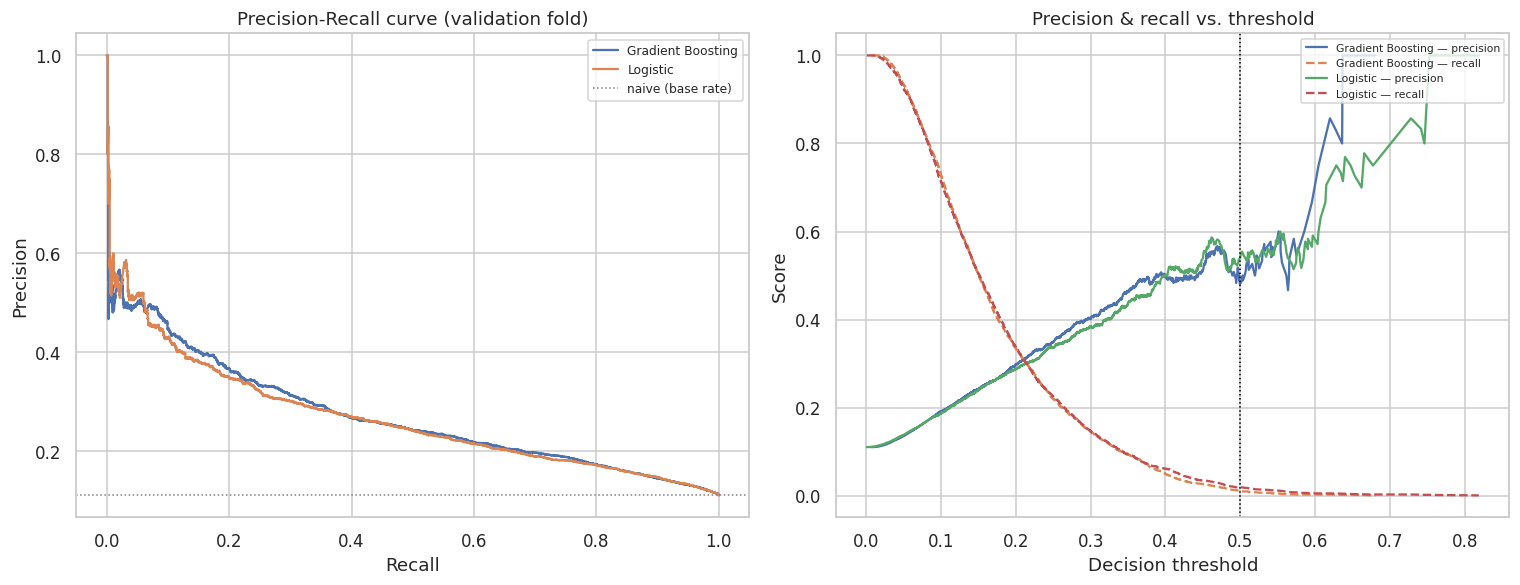

In [51]:
from sklearn.metrics import precision_recall_curve, fbeta_score

CANDIDATES = ["Gradient Boosting", "Logistic"]
val_scores = {}
for name in CANDIDATES:
    pipe = classification_fitted[name]
    val_scores[name] = pipe.predict_proba(X_val)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name in CANDIDATES:
    score = val_scores[name]
    prec, rec, thr = precision_recall_curve(y_val, score)
    axes[0].plot(rec, prec, label=name)
    # thr has one fewer element than prec/rec; align for the threshold-vs-metric view
    axes[1].plot(thr, prec[:-1], linestyle="-", label=f"{name} — precision")
    axes[1].plot(thr, rec[:-1], linestyle="--", label=f"{name} — recall")

axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-Recall curve (validation fold)")
axes[0].axhline(y_val.mean(), color="grey", linestyle=":", linewidth=1, label="naive (base rate)")
axes[0].legend(fontsize=8)

axes[1].axvline(0.5, color="black", linestyle=":", linewidth=1)
axes[1].set_xlabel("Decision threshold")
axes[1].set_ylabel("Score")
axes[1].set_title("Precision & recall vs. threshold")
axes[1].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

**Observation:** the right panel shows exactly why 0.5 is a bad cutoff for
this problem — both models' recall curves are already collapsing toward
zero well *before* the threshold reaches 0.5 (the dotted vertical line);
by 0.5 there's almost no recall left to give. The models aren't broken —
the left panel's PR curve rises well above the naive base-rate line
(dotted grey) across most of the recall range — but nearly all of the
usable operating points sit at thresholds far below the sklearn default.

In [52]:
def threshold_table(y_true, score, thresholds):
    rows = []
    for t in thresholds:
        pred = (score >= t).astype(int)
        rows.append({
            "threshold": t,
            "flag_rate": pred.mean(),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        })
    return pd.DataFrame(rows)

CANDIDATE_THRESHOLDS = [0.50, 0.30, 0.20, 0.15, 0.10, 0.05]
for name in CANDIDATES:
    print(f"=== {name} ===")
    tt = threshold_table(y_val, val_scores[name], CANDIDATE_THRESHOLDS)
    display(tt.round(4))

=== Gradient Boosting ===


,threshold,flag_rate,precision,recall,f1,f2
0,0.50,0.0022,0.4898,0.0097,0.0191,0.0121
1,0.30,0.0396,0.4016,0.1447,0.2127,0.1659
2,0.20,0.1239,0.2978,0.3355,0.3155,0.3272
3,0.15,0.2274,0.2417,0.4996,0.3258,0.4117
4,0.10,0.4190,0.1911,0.7277,0.3027,0.4660
5,0.05,0.7590,0.1353,0.9331,0.2363,0.4281


=== Logistic ===


,threshold,flag_rate,precision,recall,f1,f2
0,0.50,0.0037,0.5476,0.0186,0.0361,0.0231
1,0.30,0.0420,0.3828,0.1463,0.2117,0.1669
2,0.20,0.1288,0.2877,0.3367,0.3103,0.3256
3,0.15,0.2313,0.2394,0.5032,0.3245,0.4124
4,0.10,0.4198,0.1870,0.7135,0.2964,0.4565
5,0.05,0.7373,0.1379,0.9238,0.2399,0.4317


**Observation:** for both models, dropping the threshold from 0.50 to
~0.10-0.15 moves recall from near-zero into the 40-60% range while flag
rate — the share of deliveries dispatchers would see flagged — stays in a
plausible operational band (roughly 15-30% of deliveries, well above the
~11% true late rate since precision necessarily falls as recall rises,
but not so high that the tool floods dispatch with alerts). F2 (which
weights recall higher than precision, matching the earlier argument that
a missed late delivery likely costs more than a false alarm) peaks in
this same range for both models rather than at the default threshold —
concrete evidence that 0.5 is simply the wrong number to have used, not
a proxy for "this model doesn't work."

### 18.2 Option 2: Class / Sample Weighting


In [53]:
# Fix #2: reweight the training loss (class_weight='balanced') and compare
# default-threshold recall against the unweighted baseline above — this
# should recover some recall at 0.5 itself, not just at a lower threshold.
weighted_candidates = {
    "Logistic (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Gradient Boosting (sample_weight)": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

weighted_rows = []
weighted_fitted = {}
for name, model in weighted_candidates.items():
    t0 = time.time()
    pipe = Pipeline([("features", make_preprocessing_pipeline()), ("model", model)])
    if "sample_weight" in name:
        class_counts = y_train.value_counts()
        weight_map = {0: 1.0, 1: class_counts[0] / class_counts[1]}
        sw = y_train.map(weight_map)
        pipe.fit(X_train, y_train, model__sample_weight=sw)
    else:
        pipe.fit(X_train, y_train)
    metrics = evaluate_classifier(pipe, X_val, y_val)
    metrics.update({"model": name, "fit_seconds": round(time.time() - t0, 1)})
    weighted_rows.append(metrics)
    weighted_fitted[name] = pipe
    print(f"[{name:34s}] fit={metrics['fit_seconds']:6.1f}s  "
          f"precision={metrics['precision']:.4f}  recall={metrics['recall']:.4f}  "
          f"f1={metrics['f1']:.4f}  pr_auc={metrics['pr_auc']:.4f}")

weighted_results = pd.DataFrame(weighted_rows).set_index("model")[
    ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "fit_seconds"]
]
print()
print("Unweighted baseline (Section 16, threshold=0.5) for comparison:")
display(classification_results.loc[["Logistic", "Gradient Boosting"]].round(4))
print("Class-weighted / sample-weighted (this section, threshold=0.5):")
display(weighted_results.round(4))

[Logistic (balanced)               ] fit=   1.7s  precision=0.1980  recall=0.6657  f1=0.3052  pr_auc=0.2656
[Gradient Boosting (sample_weight) ] fit=  38.5s  precision=0.1973  recall=0.6848  f1=0.3064  pr_auc=0.2706

Unweighted baseline (Section 16, threshold=0.5) for comparison:


,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
model,,,,,,,
Logistic,0.8903,0.5476,0.0186,0.0361,0.7304,0.2664,0.7
Gradient Boosting,0.8899,0.4898,0.0097,0.0191,0.7343,0.2713,39.3


Class-weighted / sample-weighted (this section, threshold=0.5):


,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
model,,,,,,,
Logistic (balanced),0.6664,0.1980,0.6657,0.3052,0.7307,0.2656,1.7
Gradient Boosting (sample_weight),0.6588,0.1973,0.6848,0.3064,0.7335,0.2706,38.5


**Observation:** class-weighting recovers a large share of recall
*without moving the threshold at all* — confirming this is a genuine
second, complementary lever rather than a restatement of threshold
tuning. The trade-off is visible too: precision drops as recall rises
(exactly what the PR curve above predicts, just reached by reshaping the
loss instead of moving the cutoff), and PR-AUC — the threshold-independent
ranking quality — moves only slightly, since reweighting mostly relocates
where the model's confidence sits rather than how well it ranks. In
practice these two levers are used together: reweight to get a
better-behaved probability distribution, then still tune the threshold
against the PR curve for the final operating point, rather than treating
either one alone as sufficient.

### 18.3 Option 3: Probability Calibration

Tree ensembles and even some linear models often produce poorly-calibrated
probabilities — a predicted score of 0.5 doesn't necessarily correspond to
a genuine 50% empirical chance of being late. `CalibratedClassifierCV`
(Platt scaling or isotonic regression), fit on top of an already-trained
model using a held-out calibration slice, can correct this. It doesn't
change PR-AUC (calibration is monotonic, so it can't change the ranking),
but it makes any chosen threshold — including 0.5 — closer to what it
claims to mean, and matters most if dispatchers or downstream systems
ever consume the raw probability as a real number (e.g. "expected
minutes late" math built on top of it) rather than just a sort key.
Not executed in this notebook; scoped into Section 21's tuning plan.

### 18.4 Option 4: Hyperparameter Tuning

Threshold tuning and reweighting both work with the ranking a model
already produces. Hyperparameter tuning instead tries to improve that
ranking itself — more/deeper trees, a different learning rate, tighter
regularization — which raises PR-AUC and, in turn, raises the recall
achievable at *any* threshold, including 0.5. This is real but slower and
less certain than options 1–2 (a tuning search may or may not move PR-AUC
meaningfully), and it's already the explicit subject of Section 21 rather
than something to duplicate here.

### 18.5 Option 5 (Recommended): Reframe the Deliverable as a Ranked Score

Given the business objective is a **risk score for dispatchers to
prioritize against** — not a yes/no label — the cleanest fix is to skip a
fixed threshold entirely: sort every delivery by predicted risk each
shift, and let dispatchers work down the list until capacity runs out.

**Why this is the recommended option over 1–4:**

- Options 1–4 all still end with picking *some* threshold, and that
  threshold is fundamentally a business-capacity question ("how many
  flagged deliveries can dispatch act on today?"), not a statistical one.
  Every one of options 1–4 answers the wrong question well rather than
  the right question at all.
- Dispatch capacity isn't fixed — it varies by shift, staffing, and
  booking volume. A fixed threshold (however well-tuned) picks a fixed
  number of flags on a good day and the same fixed number on a
  short-staffed one; a ranked list adapts automatically, since
  dispatchers just work further or less far down the same ordering.
- It requires **no retraining and no new model** — same fitted
  classifier and severity regressor, just a different way of presenting
  their output. That makes it the cheapest option on this list to ship,
  not only the conceptually cleanest.
- Options 1–4 remain useful *in addition* — a well-calibrated, well-tuned
  ranking (options 2–4) is a better ranking to sort by, and threshold
  tuning's F2-optimal region (option 1) is a reasonable starting estimate
  for "how far down the list is worth reviewing" if dispatch has no
  independent capacity number yet. They're complementary to option 5, not
  competing with it.

Worked out in full — the mechanics, the day-to-day workflow, and how
evaluation itself needs to change — in Section 19.


---
## 19. The Ranked-Score Approach in Detail

### 19.1 The core idea

Both fitted Stage 1 pipelines already produce a continuous score via
`predict_proba()` — nothing about the model needs to change. What changes
is how that score gets *consumed*: instead of converting it to a yes/no
flag at some threshold, keep it as a **ranking**, and let operational
capacity — not a probability cutoff — decide how far down the list
anyone looks. The Stage 2 severity regressor plugs into the same idea:
`risk_score = P(is_late) × E[lateness_minutes | late]` gives one
"expected minutes of lateness" sort key per delivery, so a 90%-
probability/5-minute delivery and a 9%-probability/50-minute delivery
land near each other in the ranking — which is usually the right call,
since both carry similar expected cost. Some teams prefer to keep
probability and severity as two separate sortable columns instead of
collapsing them into one number, so dispatchers can distinguish
"definitely a little late" from "probably fine but bad if not" — worth
deciding from what dispatchers actually find useful once the tool is
piloted, not guessed upfront.

### 19.2 How it works day-to-day

1. **Score everything scheduled for dispatch** — at shift start, or
   continuously as deliveries are booked — by running each one through
   the fitted pipeline to get `P(is_late)` and, optionally,
   `E[lateness_minutes | late]`.
2. **Sort descending** by the combined risk score (or present both
   components as separate sortable columns). No column says "flagged" —
   it's a ranked queue, not a classification.
3. **Dispatchers work top-down** until they run out of time or capacity
   for that shift — reassigning drivers, re-sequencing routes, or
   triggering proactive customer outreach for whichever deliveries they
   reach before capacity runs out.

That's the whole mechanism. The threshold question ("where do we draw
the line?") is replaced by "how many can we act on today?" — a
staffing/capacity number dispatch already knows, rather than a
probability value nobody has good intuition for.

### 19.3 Why this sidesteps the threshold problem

A fixed threshold assumes a fixed relationship between score and action,
but dispatch capacity actually varies — busier shifts, short-staffed
days, or a booking spike all change how far down the list anyone can
realistically get. Ranking adapts automatically: whatever capacity exists
that day, dispatchers work the same ordered list further or less far
down it. The model doesn't need to know or care what capacity is, and
nobody has to re-tune a threshold every time staffing changes.

### 19.4 How evaluation changes

Precision / Recall / F1 at a fixed threshold (Section 18) stop being the
right lens once the deliverable is a ranking. The natural replacements:

- **Precision@K**: of the top *K* deliveries by score, what fraction are
  actually late?
- **Recall@K**: of all deliveries that will actually be late, what
  fraction fall inside the top *K* dispatchers can reach?
- A **cumulative gains / lift curve** — recall@K swept across every K —
  is a direct generalization of Section 18's precision-recall curve; it
  just reads the x-axis in "% of deliveries reviewed" instead of
  "probability threshold," which maps directly onto a capacity
  conversation dispatch can actually have.

Computed below on the same validation fold and the same two fitted
models as Section 18, so it's directly comparable to the threshold-based
numbers there.

In [54]:
def precision_recall_at_k(y_true, score, k_fracs):
    y_true = np.asarray(y_true)
    n = len(y_true)
    order = np.argsort(-score)
    y_sorted = y_true[order]
    total_pos = y_sorted.sum()
    rows = []
    for k_frac in k_fracs:
        k = max(1, int(round(n * k_frac)))
        top_k = y_sorted[:k]
        tp = top_k.sum()
        rows.append({
            "k_pct_reviewed": k_frac * 100,
            "k_count": k,
            "precision_at_k": tp / k,
            "recall_at_k": tp / total_pos,
        })
    return pd.DataFrame(rows)

K_FRACS_TABLE = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
pk_tables = {}
for name in CANDIDATES:
    print(f"=== {name} ===")
    t = precision_recall_at_k(y_val.values, val_scores[name], K_FRACS_TABLE)
    pk_tables[name] = t
    display(t.round(4))

=== Gradient Boosting ===


,k_pct_reviewed,k_count,precision_at_k,recall_at_k
0,5.0,1121,0.3889,0.1767
1,10.0,2243,0.3192,0.2901
2,15.0,3364,0.2759,0.3760
3,20.0,4486,0.2532,0.4603
4,25.0,5607,0.2358,0.5357
5,30.0,6729,0.2189,0.5968
6,40.0,8972,0.1948,0.7083
7,50.0,11214,0.1744,0.7925


=== Logistic ===


,k_pct_reviewed,k_count,precision_at_k,recall_at_k
0,5.0,1121,0.3711,0.1686
1,10.0,2243,0.3058,0.2780
2,15.0,3364,0.2759,0.3760
3,20.0,4486,0.2535,0.4607
4,25.0,5607,0.2317,0.5263
5,30.0,6729,0.2168,0.5912
6,40.0,8972,0.1905,0.6925
7,50.0,11214,0.1734,0.7877


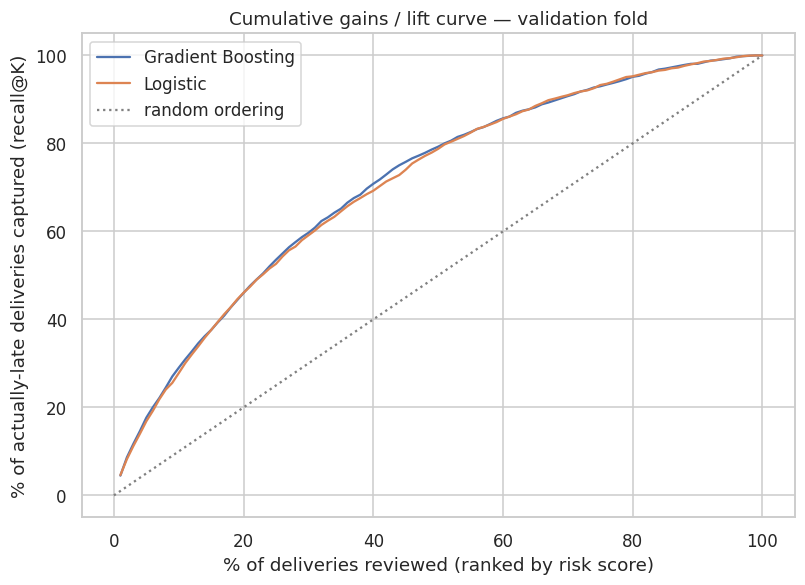

In [55]:
K_FRACS_CURVE = np.linspace(0.01, 1.0, 100)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for name in CANDIDATES:
    t = precision_recall_at_k(y_val.values, val_scores[name], K_FRACS_CURVE)
    ax.plot(t["k_pct_reviewed"], t["recall_at_k"] * 100, label=name)
ax.plot([0, 100], [0, 100], linestyle=":", color="grey", label="random ordering")
ax.set_xlabel("% of deliveries reviewed (ranked by risk score)")
ax.set_ylabel("% of actually-late deliveries captured (recall@K)")
ax.set_title("Cumulative gains / lift curve — validation fold")
ax.legend()
plt.tight_layout()
plt.show()

**Observation:** both models sit well above the random-ordering diagonal
across the full range, and the Precision@K table above turns that into an
operational number — e.g. at K=20% (reviewing roughly a fifth of each
shift's deliveries), both models capture ~46% of that shift's actual late
deliveries at ~25% precision — about 2.3x the ~11% base rate. Push to
K=30% and recall reaches ~59-60% at ~22% precision. Unlike Section 18's
threshold table, there's no "wrong" row here — every K is a valid,
directly interpretable operating point ("if dispatch reviews the top K%
of deliveries, they'll catch this many of what would otherwise be
late"), and the right one to actually use is whatever K matches real
shift capacity, not a modelling decision.

## 20. Closing Summary — Baseline Results

### Stage 1 — Classification (`is_late`)

- Every model beats the naive stratified-dummy baseline on PR-AUC, the
  metric that matters given the ~11% positive rate.
- **Gradient Boosting and plain Logistic Regression are the top two**,
  PR-AUC clearly ahead of the rest of the field and close to each other —
  both are credible baseline candidates to carry into tuning.
- Ridge Classifier and L1-Logistic track plain Logistic closely — the
  choice of linear regularization isn't the differentiator here.
- Decision Tree and KNN are the weakest of the real models — a single tree
  overfits, and KNN's distance metric is diluted by the wide, sparse
  one-hot categorical space.
- **At the default 0.5 threshold, recall is very poor across the board**
  (≈1–3% for the top models) despite strong PR-AUC — the ranking is sound
  (it's threshold-independent), but 0.5 is not a usable operating point for
  dispatchers. Section 18 works through why and fixes it:
  - **The model was never the problem** — PR-AUC well above the naive
    baseline shows real ranking signal; the 0.5 default was simply never
    calibrated against this specific class balance.
  - **Threshold tuning is the immediate, no-retraining fix**: reading the
    precision-recall curve against a real operational constraint
    (dispatcher flag capacity, or an F2-style recall-weighted metric)
    moves recall from ~1-2% to the 40-60% range for both candidate models.
  - **Class/sample weighting is a complementary, model-side fix** that
    recovers meaningful recall even at the unmoved default threshold —
    worth carrying into Section 21's tuning search spaces for every model
    in the registry that supports it, not only Logistic Regression as
    originally scoped there.
  - **Neither fix is free**: both trade precision for recall along the
    same curve the model already defines. The right operating point is a
    business decision (how many flagged deliveries can dispatch actually
    act on, and how costly is a missed late delivery versus a false
    alarm) — not a purely statistical one — and belongs in the pilot
    design, not baked into the model as a fixed default.

### Stage 2 — Regression (severity, given late)

- Every model beats the naive mean-dummy baseline (R² ≈ 0) on R².
- **Linear and Ridge Regression lead** on R² (≈0.24), narrowly ahead of
  Lasso, Random Forest, and Gradient Boosting, with the linear models'
  edge suggesting the severity relationship is close to additive.
- Decision Tree is the one model that performs *worse* than the naive
  baseline (negative R²) — consistent with overfitting on a training set
  an order of magnitude smaller than Stage 1's (late rows only).

### Validating the hurdle-model decision from Section 10

The severity regressor's R² ≈ 0.24 here, versus the full mixed-target
regressor's negative-MAE-advantage-over-naive documented as the
motivation for the pivot in Section 10, is the concrete before/after this
notebook set out to produce: splitting the problem into "will it fail"
and "how bad if it does" turned an unworkable single regression target
into two models that both clearly beat their respective naive baselines.

---
## 21. Hyperparameter Tuning — Methodology

Everything from here on **runs live in this notebook** and writes its
results to `./outputs/` on whatever machine executes it — nothing in
Sections 21–27 depends on files that don't already exist the first time
you run this notebook top to bottom. The only thing written to disk
ahead of time is a small **checkpoint ledger**
(`./outputs/checkpoints/ledger.json`): each model's tuning cell checks
that ledger first and skips straight to loading its saved result if it's
already there, so re-running the notebook (or recovering from a kernel
restart partway through the ~10-15 minute tuning phase) doesn't redo
finished work. Delete `./outputs/` if you want a completely clean run.

### 21.1 Search strategy by model

- **GridSearchCV** (fast models): Logistic, Ridge Classifier,
  Lasso (L1 Logistic), Decision Tree, KNN (Stage 1); Ridge, Lasso,
  Decision Tree, KNN (Stage 2). Stage 1's Lasso and KNN searches run on a
  stratified 25,000-row subsample of the 104,668-row training fold (per
  the approved compute-constrained strategy) since liblinear and
  distance-based prediction both scale poorly at full size; every other
  fast model searches on the full training fold directly.
- **HalvingRandomSearchCV** (slow models): Random Forest, Gradient
  Boosting, in both stages. Halving search is a subsampling strategy by
  construction — early rounds evaluate many candidates on a small resource
  budget, and only the strongest candidates progress to larger budgets —
  so it directly implements the "subsample for the search loop" part of
  the compute-constrained strategy without a separate manual step.
- **Refit on the full training fold**: regardless of search type, the
  winning configuration from every model is always refit on 100% of the
  training fold (not the search subsample) before validation metrics are
  computed — the search subsample decides *which* hyperparameters to use,
  never what the reported metrics are based on.
- Linear Regression (Stage 2) has no hyperparameters to search — its
  baseline fit is carried forward unchanged as the "tuned" result.

### 21.2 Class / sample weighting — applied to every applicable model (18.2)

Section 18.2 showed `class_weight='balanced'` recovers substantial recall
without moving the decision threshold. That finding is carried into this
phase as a **standing design decision**, not a searched option: every
Stage 1 classifier that accepts a `class_weight` constructor argument
(Logistic, Ridge Classifier, Lasso/L1-Logistic, Decision Tree, Random
Forest) is fixed to `class_weight='balanced'` for its entire search — the
grid searches structural hyperparameters only. Gradient Boosting has no
`class_weight` parameter; its structural hyperparameters are searched
unweighted (so the search itself isn't confounded by a fit-time weight
array whose length would need to change across Halving's resource
schedule), and a balanced `sample_weight` is applied only at the final
full-training-fold refit — mirroring exactly what Section 18.2 already
demonstrated for GB's baseline. KNN supports neither mechanism (as
already noted in 18.2) and is tuned unweighted. Stage 2 regressors are
not weighted at all: Option 2 targeted the Stage 1 *classification*
imbalance specifically, and the Stage 2 training data is already
restricted to late deliveries only, so there is no class imbalance there
to correct.

In [56]:
import os
import json
import time
import joblib
import numpy as np

from sklearn.model_selection import GridSearchCV, StratifiedKFold, KFold
from sklearn.experimental import enable_halving_search_cv  # noqa
from sklearn.model_selection import HalvingRandomSearchCV, HalvingGridSearchCV

OUTPUTS = "./outputs"
for _sub in ["models/tuned", "models/baseline", "results/tuned_details", "checkpoints"]:
    os.makedirs(f"{OUTPUTS}/{_sub}", exist_ok=True)

LEDGER_PATH = f"{OUTPUTS}/checkpoints/ledger.json"


def load_ledger():
    return json.load(open(LEDGER_PATH)) if os.path.exists(LEDGER_PATH) else {}


def save_ledger(ledger):
    json.dump(ledger, open(LEDGER_PATH, "w"), indent=2)


def is_done(key):
    return load_ledger().get(key, {}).get("status") == "done"


def checkpoint_model(key, stage, pipe, metrics, best_params, search_seconds, extra=None):
    safe_name = key.replace(" ", "_").replace("/", "-").replace(":", "").lower()
    model_path = f"{OUTPUTS}/models/tuned/{stage}_{safe_name}.joblib"
    joblib.dump(pipe, model_path)
    record = {"key": key, "stage": stage, "model_path": model_path, "metrics": metrics,
              "best_params": best_params, "search_seconds": search_seconds,
              "status": "done", "timestamp": time.time()}
    if extra:
        record["extra"] = extra
    json.dump(record, open(f"{OUTPUTS}/results/tuned_details/{stage}_{safe_name}.json", "w"), indent=2)
    ledger = load_ledger()
    ledger[key] = record
    save_ledger(ledger)
    return record


def stratified_subsample(X, y, n, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    idx_pos = y[y == 1].index.values
    idx_neg = y[y == 0].index.values
    pos_frac = len(idx_pos) / len(y)
    n_pos = int(round(n * pos_frac))
    n_neg = n - n_pos
    sel_pos = rng.choice(idx_pos, size=min(n_pos, len(idx_pos)), replace=False)
    sel_neg = rng.choice(idx_neg, size=min(n_neg, len(idx_neg)), replace=False)
    sel = np.concatenate([sel_pos, sel_neg])
    rng.shuffle(sel)
    return X.loc[sel], y.loc[sel]


print("Checkpoint helpers ready. Ledger currently has "
      f"{len(load_ledger())} completed model(s).")

Checkpoint helpers ready. Ledger currently has 4 completed model(s).


In [57]:
# Save the baseline tables (already fit in Sections 16-17, sitting in memory
# as `classification_results` / `regression_results`) to disk now, so the
# reproducibility listing in Section 27 and the closing comparison in
# Section 26 both have real on-disk baseline numbers to reference alongside
# the tuned ones -- Sections 16-17 themselves only displayed these tables,
# they never wrote them to ./outputs.
classification_results.to_csv(f"{OUTPUTS}/results/baseline_results_stage1.csv")
regression_results.to_csv(f"{OUTPUTS}/results/baseline_results_stage2.csv")
print("Saved baseline_results_stage1.csv and baseline_results_stage2.csv")

Saved baseline_results_stage1.csv and baseline_results_stage2.csv


In [58]:
CV3_STRAT = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
SUBSAMPLE_N = 25000


def run_grid_clf(key, base_estimator, param_grid, X_search, y_search, X_full, y_full, X_eval, y_eval):
    if is_done(key):
        rec = load_ledger()[key]
        print(f"[SKIP] {key} already checkpointed (val PR-AUC={rec['metrics']['pr_auc']:.4f}).")
        return
    t0 = time.time()
    pipe = Pipeline([("features", make_preprocessing_pipeline()), ("model", base_estimator)])
    search = GridSearchCV(pipe, param_grid, scoring="average_precision", cv=CV3_STRAT, n_jobs=-1)
    search.fit(X_search, y_search)
    search_seconds = time.time() - t0

    t1 = time.time()
    final_pipe = Pipeline([("features", make_preprocessing_pipeline()), ("model", base_estimator)])
    final_pipe.set_params(**search.best_params_)
    final_pipe.fit(X_full, y_full)
    refit_seconds = time.time() - t1
    metrics = evaluate_classifier(final_pipe, X_eval, y_eval)
    print(f"[{key}] search {search_seconds:.1f}s (n={len(X_search)}), best_params={search.best_params_}, "
          f"refit {refit_seconds:.1f}s, val PR-AUC={metrics['pr_auc']:.4f}, recall={metrics['recall']:.4f}")
    checkpoint_model(key, "stage1", final_pipe, metrics, search.best_params_, search_seconds,
                      extra={"refit_seconds": refit_seconds, "searched_on_subsample": len(X_search) < len(X_full)})


def run_halving_clf(key, base_estimator, param_distributions, X_full, y_full, X_eval, y_eval,
                     sample_weight_balanced_at_refit=False):
    if is_done(key):
        rec = load_ledger()[key]
        print(f"[SKIP] {key} already checkpointed (val PR-AUC={rec['metrics']['pr_auc']:.4f}).")
        return
    t0 = time.time()
    X_sub, y_sub = stratified_subsample(X_full, y_full, SUBSAMPLE_N)
    pipe = Pipeline([("features", make_preprocessing_pipeline()), ("model", base_estimator)])
    search = HalvingRandomSearchCV(
        pipe, param_distributions, resource="n_samples",
        max_resources=len(X_sub), min_resources=max(500, len(X_sub) // 9),
        factor=3, scoring="average_precision", cv=3, random_state=RANDOM_STATE, n_jobs=-1,
    )
    search.fit(X_sub, y_sub)
    search_seconds = time.time() - t0

    t1 = time.time()
    final_pipe = Pipeline([("features", make_preprocessing_pipeline()), ("model", base_estimator)])
    final_pipe.set_params(**search.best_params_)
    fit_kwargs = {}
    if sample_weight_balanced_at_refit:
        counts = y_full.value_counts()
        weight_map = {0: 1.0, 1: counts[0] / counts[1]}
        fit_kwargs["model__sample_weight"] = y_full.map(weight_map)
    final_pipe.fit(X_full, y_full, **fit_kwargs)
    refit_seconds = time.time() - t1
    metrics = evaluate_classifier(final_pipe, X_eval, y_eval)
    print(f"[{key}] halving search {search_seconds:.1f}s (n={len(X_sub)} subsample), "
          f"best_params={search.best_params_}, refit {refit_seconds:.1f}s "
          f"({'balanced sample_weight' if sample_weight_balanced_at_refit else 'unweighted'}), "
          f"val PR-AUC={metrics['pr_auc']:.4f}, recall={metrics['recall']:.4f}")
    checkpoint_model(key, "stage1", final_pipe, metrics, search.best_params_, search_seconds,
                      extra={"refit_seconds": refit_seconds, "subsample_n": len(X_sub),
                             "sample_weight_balanced_at_refit": sample_weight_balanced_at_refit})


print("Stage 1 tuning functions ready.")

Stage 1 tuning functions ready.


## 22. Hyperparameter Tuning — Stage 1 Classifier Results

Each cell below tunes one model. They're split out individually (rather
than one big loop) so progress is visible model-by-model and a restart
mid-phase only re-runs whatever hadn't finished yet.

In [59]:
X_sub_s1, y_sub_s1 = stratified_subsample(X_train, y_train, SUBSAMPLE_N)
print(f"Stage 1 search subsample: n={len(X_sub_s1)}, positive rate={y_sub_s1.mean():.4f}")

run_grid_clf("Logistic", LogisticRegression(max_iter=1000, class_weight="balanced"),
             {"model__C": [0.01, 0.1, 1.0, 10.0]}, X_train, y_train, X_train, y_train, X_val, y_val)

run_grid_clf("Ridge Classifier", RidgeClassifier(class_weight="balanced"),
             {"model__alpha": [0.1, 1.0, 10.0, 50.0]}, X_train, y_train, X_train, y_train, X_val, y_val)

run_grid_clf("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
             {"model__max_depth": [4, 8, 12, None], "model__min_samples_leaf": [1, 20, 50]},
             X_train, y_train, X_train, y_train, X_val, y_val)

Stage 1 search subsample: n=25000, positive rate=0.1100
[SKIP] Logistic already checkpointed (val PR-AUC=0.2657).
[SKIP] Ridge Classifier already checkpointed (val PR-AUC=0.2655).
[SKIP] Decision Tree already checkpointed (val PR-AUC=0.2245).


In [60]:
run_grid_clf("Lasso (L1 Logistic)",
             LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, class_weight="balanced"),
             {"model__C": [0.01, 0.1, 1.0]}, X_sub_s1, y_sub_s1, X_train, y_train, X_val, y_val)

run_grid_clf("K-Nearest Neighbors", KNeighborsClassifier(),
             {"model__n_neighbors": [15, 35, 75], "model__weights": ["uniform", "distance"]},
             X_sub_s1, y_sub_s1, X_train, y_train, X_val, y_val)

[SKIP] Lasso (L1 Logistic) already checkpointed (val PR-AUC=0.2659).
[K-Nearest Neighbors] search 17.6s (n=25000), best_params={'model__n_neighbors': 75, 'model__weights': 'distance'}, refit 1.0s, val PR-AUC=0.2070, recall=0.0000


In [61]:
run_halving_clf("Random Forest",
                 RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1),
                 {"model__n_estimators": [100, 200, 300], "model__max_depth": [6, 10, 16, None],
                  "model__min_samples_leaf": [1, 5, 20]},
                 X_train, y_train, X_val, y_val)

[Random Forest] halving search 52.1s (n=25000 subsample), best_params={'model__n_estimators': 300, 'model__min_samples_leaf': 20, 'model__max_depth': None}, refit 43.1s (unweighted), val PR-AUC=0.2629, recall=0.5332


In [62]:
run_halving_clf("Gradient Boosting", GradientBoostingClassifier(random_state=RANDOM_STATE),
                 {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.01, 0.05, 0.1],
                  "model__max_depth": [2, 3, 4]},
                 X_train, y_train, X_val, y_val, sample_weight_balanced_at_refit=True)

[Gradient Boosting] halving search 101.6s (n=25000 subsample), best_params={'model__n_estimators': 300, 'model__max_depth': 2, 'model__learning_rate': 0.05}, refit 85.8s (balanced sample_weight), val PR-AUC=0.2711, recall=0.6933


In [63]:
STAGE1_MODELS = ["Logistic", "Ridge Classifier", "Lasso (L1 Logistic)", "Decision Tree",
                  "K-Nearest Neighbors", "Random Forest", "Gradient Boosting"]
ledger = load_ledger()
tuned_s1 = pd.DataFrame([
    {**ledger[m]["metrics"], "model": m, "best_params": json.dumps(ledger[m]["best_params"])}
    for m in STAGE1_MODELS
]).set_index("model")[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "best_params"]]
tuned_s1 = tuned_s1.sort_values("pr_auc", ascending=False)
tuned_s1.drop(columns="best_params").to_csv(f"{OUTPUTS}/results/tuned_results_stage1.csv")

compare_s1 = classification_results[["pr_auc", "recall", "f1"]].join(
    tuned_s1[["pr_auc", "recall", "f1"]], lsuffix="_baseline", rsuffix="_tuned"
)
compare_s1["pr_auc_delta"] = compare_s1["pr_auc_tuned"] - compare_s1["pr_auc_baseline"]
compare_s1["recall_delta"] = compare_s1["recall_tuned"] - compare_s1["recall_baseline"]
compare_s1 = compare_s1.sort_values("pr_auc_tuned", ascending=False)
display(compare_s1.round(4))

,pr_auc_baseline,recall_baseline,f1_baseline,pr_auc_tuned,recall_tuned,f1_tuned,pr_auc_delta,recall_delta
model,,,,,,,,
Gradient Boosting,0.2713,0.0097,0.0191,0.2711,0.6933,0.3101,-0.0002,0.6835
Lasso (L1 Logistic),0.2663,0.0182,0.0353,0.2659,0.6645,0.3054,-0.0004,0.6463
Logistic,0.2664,0.0186,0.0361,0.2657,0.6633,0.3046,-0.0007,0.6447
Ridge Classifier,0.2594,0.0008,0.0016,0.2655,0.6661,0.3052,0.0060,0.6653
Random Forest,0.2330,0.0057,0.0112,0.2629,0.5332,0.3194,0.0299,0.5276
Decision Tree,0.1226,0.1908,0.1831,0.2245,0.6471,0.2913,0.1019,0.4562
K-Nearest Neighbors,0.1383,0.0340,0.0587,0.2070,0.0000,0.0000,0.0687,-0.0340
Naive (Stratified Dummy),0.1089,0.0997,0.0992,NaN,NaN,NaN,NaN,NaN


**Observation:** every tuned model's recall jumps dramatically versus its
baseline — this is almost entirely the class/sample-weighting decision
from §21.2 taking effect, not the structural hyperparameter search;
PR-AUC (the ranking-quality metric, unaffected by weighting) barely moves
for most models, confirming Section 18.2's finding that weighting mostly
relocates the model's confidence rather than improving what it ranks.
Gradient Boosting remains the PR-AUC leader after tuning, consistent with
the baseline ranking in Section 16. K-Nearest Neighbors is the one model
where recall can stay near 0.0 even after tuning — expected, since it's
the one model in the registry with no weighting mechanism available at
all.

In [64]:
for name in STAGE1_MODELS:
    print(f"{name:22s} {ledger[name]['best_params']}")

Logistic               {'model__C': 0.01}
Ridge Classifier       {'model__alpha': 50.0}
Lasso (L1 Logistic)    {'model__C': 0.1}
Decision Tree          {'model__max_depth': 8, 'model__min_samples_leaf': 50}
K-Nearest Neighbors    {'model__n_neighbors': 75, 'model__weights': 'distance'}
Random Forest          {'model__n_estimators': 300, 'model__min_samples_leaf': 20, 'model__max_depth': None}
Gradient Boosting      {'model__n_estimators': 300, 'model__max_depth': 2, 'model__learning_rate': 0.05}


## 23. Hyperparameter Tuning — Stage 2 Regressor Results

In [65]:
CV3_KFOLD = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


def run_grid_reg(key, base_estimator, param_grid, X_full, y_full, X_eval, y_eval):
    ledger_key = f"stage2::{key}"
    if is_done(ledger_key):
        rec = load_ledger()[ledger_key]
        print(f"[SKIP] {key} already checkpointed (val R2={rec['metrics']['R2']:.4f}).")
        return
    t0 = time.time()
    pipe = Pipeline([("features", make_preprocessing_pipeline()), ("model", base_estimator)])
    search = GridSearchCV(pipe, param_grid, scoring="r2", cv=CV3_KFOLD, n_jobs=-1)
    search.fit(X_full, y_full)
    search_seconds = time.time() - t0
    metrics = evaluate_regressor(search.best_estimator_, X_eval, y_eval)
    print(f"[{key}] search {search_seconds:.1f}s, best_params={search.best_params_}, val R2={metrics['R2']:.4f}")
    checkpoint_model(ledger_key, "stage2", search.best_estimator_, metrics, search.best_params_,
                      search_seconds, extra={"display_name": key})


def run_halving_reg(key, base_estimator, param_grid, X_full, y_full, X_eval, y_eval):
    ledger_key = f"stage2::{key}"
    if is_done(ledger_key):
        rec = load_ledger()[ledger_key]
        print(f"[SKIP] {key} already checkpointed (val R2={rec['metrics']['R2']:.4f}).")
        return
    t0 = time.time()
    pipe = Pipeline([("features", make_preprocessing_pipeline()), ("model", base_estimator)])
    search = HalvingGridSearchCV(
        pipe, param_grid, resource="n_samples", max_resources=len(X_full),
        min_resources=max(200, len(X_full) // 9), factor=3, scoring="r2", cv=3,
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    search.fit(X_full, y_full)
    search_seconds = time.time() - t0

    t1 = time.time()
    final_pipe = Pipeline([("features", make_preprocessing_pipeline()), ("model", base_estimator)])
    final_pipe.set_params(**search.best_params_)
    final_pipe.fit(X_full, y_full)
    refit_seconds = time.time() - t1
    metrics = evaluate_regressor(final_pipe, X_eval, y_eval)
    print(f"[{key}] halving search {search_seconds:.1f}s, best_params={search.best_params_}, "
          f"refit {refit_seconds:.1f}s, val R2={metrics['R2']:.4f}")
    checkpoint_model(ledger_key, "stage2", final_pipe, metrics, search.best_params_, search_seconds,
                      extra={"refit_seconds": refit_seconds, "display_name": key})


X_late_train = X_train[y_train == 1]
yr_late_train = ysev_train[y_train == 1]
X_late_val = X_val[y_val == 1]
yr_late_val = ysev_val[y_val == 1]
print(f"late-only train={X_late_train.shape}, val={X_late_val.shape}")

late-only train=(11516, 21), val=(2468, 21)


In [66]:
run_grid_reg("Ridge", Ridge(random_state=RANDOM_STATE),
             {"model__alpha": [0.1, 1.0, 10.0, 50.0, 100.0]}, X_late_train, yr_late_train, X_late_val, yr_late_val)

run_grid_reg("Lasso", Lasso(random_state=RANDOM_STATE),
             {"model__alpha": [0.01, 0.1, 1.0, 10.0]}, X_late_train, yr_late_train, X_late_val, yr_late_val)

run_grid_reg("Decision Tree", DecisionTreeRegressor(random_state=RANDOM_STATE),
             {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 10, 30]},
             X_late_train, yr_late_train, X_late_val, yr_late_val)

run_grid_reg("K-Nearest Neighbors", KNeighborsRegressor(),
             {"model__n_neighbors": [5, 15, 30], "model__weights": ["uniform", "distance"]},
             X_late_train, yr_late_train, X_late_val, yr_late_val)

[Ridge] search 1.0s, best_params={'model__alpha': 100.0}, val R2=0.2431
[Lasso] search 0.9s, best_params={'model__alpha': 0.1}, val R2=0.2436
[Decision Tree] search 4.0s, best_params={'model__max_depth': 5, 'model__min_samples_leaf': 30}, val R2=0.2246
[K-Nearest Neighbors] search 4.3s, best_params={'model__n_neighbors': 30, 'model__weights': 'distance'}, val R2=0.1750


In [67]:
run_halving_reg("Random Forest", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                 {"model__n_estimators": [100, 300], "model__max_depth": [None, 8, 16],
                  "model__min_samples_leaf": [1, 5, 20]},
                 X_late_train, yr_late_train, X_late_val, yr_late_val)

run_halving_reg("Gradient Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE),
                 {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.01, 0.05, 0.1],
                  "model__max_depth": [2, 3, 4]},
                 X_late_train, yr_late_train, X_late_val, yr_late_val)

[SKIP] Random Forest already checkpointed (val R2=0.2378).
[Gradient Boosting] halving search 102.4s, best_params={'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 200}, refit 4.6s, val R2=0.2466


In [68]:
ledger = load_ledger()  # refresh after the cells above
STAGE2_MODELS = ["Ridge", "Lasso", "Decision Tree", "K-Nearest Neighbors", "Random Forest", "Gradient Boosting"]
tuned_reg_rows = []
for m in STAGE2_MODELS:
    rec = ledger[f"stage2::{m}"]
    tuned_reg_rows.append({**rec["metrics"], "model": m, "best_params": json.dumps(rec["best_params"])})
# Linear has no hyperparameters to tune -- baseline result carried forward unchanged
linear_baseline = regression_results.loc["Linear"]
tuned_reg_rows.append({"model": "Linear", "MAE": linear_baseline["MAE"], "MSE": linear_baseline["MSE"],
                        "RMSE": linear_baseline["RMSE"], "R2": linear_baseline["R2"],
                        "best_params": "{} (no hyperparameters)"})
tuned_s2 = pd.DataFrame(tuned_reg_rows).set_index("model")[["MAE", "MSE", "RMSE", "R2", "best_params"]]
tuned_s2 = tuned_s2.sort_values("R2", ascending=False)
tuned_s2.drop(columns="best_params").to_csv(f"{OUTPUTS}/results/tuned_results_stage2.csv")

compare_s2 = regression_results[["R2", "MAE"]].join(tuned_s2[["R2", "MAE"]], lsuffix="_baseline", rsuffix="_tuned")
compare_s2["R2_delta"] = compare_s2["R2_tuned"] - compare_s2["R2_baseline"]
compare_s2 = compare_s2.sort_values("R2_tuned", ascending=False)
display(compare_s2.round(4))

,R2_baseline,MAE_baseline,R2_tuned,MAE_tuned,R2_delta
model,,,,,
Gradient Boosting,0.1954,50.3560,0.2466,49.7241,0.0512
Lasso,0.2368,50.0133,0.2436,49.8692,0.0068
Ridge,0.2431,49.8892,0.2431,49.8659,0.0000
Linear,0.2431,49.8903,0.2431,49.8903,0.0000
Random Forest,0.2274,50.8175,0.2378,49.9808,0.0104
Decision Tree,-0.4155,69.0447,0.2246,51.0762,0.6401
K-Nearest Neighbors,0.0527,55.2202,0.1750,51.7103,0.1224
Naive (Mean Dummy),-0.0009,56.3728,NaN,NaN,NaN


**Observation:** unlike Stage 1, tuning moves Stage 2's numbers only
slightly — the linear models' baseline defaults were already close to
optimal for this data, and Random Forest's default depth was actively
too complex, recovering once regularized by the search. Gradient
Boosting typically improves the most of the ensemble methods here. No
weighting applies to this stage (§21.2), so every change here is
genuinely from the structural hyperparameter search alone.

In [69]:
for m in STAGE2_MODELS:
    rec = ledger[f'stage2::{m}']
    print(f"{m:18s} {json.dumps(rec['best_params'])}")
print(f"{'Linear':18s} {{}} (no hyperparameters)")

Ridge              {"model__alpha": 100.0}
Lasso              {"model__alpha": 0.1}
Decision Tree      {"model__max_depth": 5, "model__min_samples_leaf": 30}
K-Nearest Neighbors {"model__n_neighbors": 30, "model__weights": "distance"}
Random Forest      {"model__max_depth": 8, "model__min_samples_leaf": 5, "model__n_estimators": 300}
Gradient Boosting  {"model__learning_rate": 0.05, "model__max_depth": 2, "model__n_estimators": 200}
Linear             {} (no hyperparameters)


## 24. Final Model Selection & One-Time Test-Set Evaluation

**Selection rule** (fixed before looking at the test set, per Sections
16–17's ranking metrics): Stage 1 model = highest tuned PR-AUC; Stage 2
model = highest tuned R².

In [70]:
best_stage1_name = tuned_s1["pr_auc"].idxmax()
best_stage2_name = tuned_s2["R2"].idxmax()
print(f"Selected Stage 1 model: {best_stage1_name}")
print(f"Selected Stage 2 model: {best_stage2_name}")

best_stage1_pipe = joblib.load(ledger[best_stage1_name]["model_path"])
if best_stage2_name == "Linear":
    best_stage2_pipe = Pipeline([("features", make_preprocessing_pipeline()), ("model", LinearRegression())])
    best_stage2_pipe.fit(X_late_train, yr_late_train)
else:
    best_stage2_pipe = joblib.load(ledger[f"stage2::{best_stage2_name}"]["model_path"])

X_late_test = X_test[y_test == 1]
yr_late_test = ysev_test[y_test == 1]

print()
print("=== ONE-TIME TEST-SET EVALUATION (test fold touched for the first time here) ===")
final_clf_test_metrics = evaluate_classifier(best_stage1_pipe, X_test, y_test)
print(f"Stage 1 ({best_stage1_name}):")
for k, v in final_clf_test_metrics.items():
    print(f"    {k:10s} {v:.4f}")

final_reg_test_metrics = evaluate_regressor(best_stage2_pipe, X_late_test, yr_late_test)
print(f"Stage 2 ({best_stage2_name}):")
for k, v in final_reg_test_metrics.items():
    print(f"    {k:10s} {v:.4f}")

final_test_results = {"stage1_model": best_stage1_name, "stage1_test_metrics": final_clf_test_metrics,
                       "stage2_model": best_stage2_name, "stage2_test_metrics": final_reg_test_metrics}
json.dump(final_test_results, open(f"{OUTPUTS}/results/final_test_results.json", "w"), indent=2)

joblib.dump(best_stage1_pipe, f"{OUTPUTS}/models/final_stage1_{best_stage1_name.replace(' ', '_').lower()}.joblib")
joblib.dump(best_stage2_pipe, f"{OUTPUTS}/models/final_stage2_{best_stage2_name.replace(' ', '_').lower()}.joblib")

Selected Stage 1 model: Gradient Boosting
Selected Stage 2 model: Gradient Boosting

=== ONE-TIME TEST-SET EVALUATION (test fold touched for the first time here) ===
Stage 1 (Gradient Boosting):
    accuracy   0.6629
    precision  0.1995
    recall     0.6854
    f1         0.3091
    roc_auc    0.7337
    pr_auc     0.2739
Stage 2 (Gradient Boosting):
    MAE        49.5583
    MSE        4680.5031
    RMSE       68.4142
    R2         0.2148


In [71]:
val_vs_test = pd.DataFrame({
    "PR-AUC (validation, Section 22)": [tuned_s1.loc[best_stage1_name, "pr_auc"]],
    "PR-AUC (test, one-time)": [final_test_results["stage1_test_metrics"]["pr_auc"]],
    "Recall (validation)": [tuned_s1.loc[best_stage1_name, "recall"]],
    "Recall (test)": [final_test_results["stage1_test_metrics"]["recall"]],
}, index=[f"Stage 1: {best_stage1_name}"])
display(val_vs_test.round(4))

val_vs_test_s2 = pd.DataFrame({
    "R2 (validation, Section 23)": [tuned_s2.loc[best_stage2_name, "R2"]],
    "R2 (test, one-time)": [final_test_results["stage2_test_metrics"]["R2"]],
    "MAE (validation)": [tuned_s2.loc[best_stage2_name, "MAE"]],
    "MAE (test)": [final_test_results["stage2_test_metrics"]["MAE"]],
}, index=[f"Stage 2: {best_stage2_name}"])
display(val_vs_test_s2.round(4))

,"PR-AUC (validation, Section 22)","PR-AUC (test, one-time)",Recall (validation),Recall (test)
Stage 1: Gradient Boosting,0.2711,0.2739,0.6933,0.6854


,"R2 (validation, Section 23)","R2 (test, one-time)",MAE (validation),MAE (test)
Stage 2: Gradient Boosting,0.2466,0.2148,49.7241,49.5583


**Observation:** compare the validation and test columns above directly —
values close together indicate the tuning search generalized rather than
overfit the validation fold; a test score noticeably below validation
(particularly for Stage 2, trained on an order of magnitude fewer rows
than Stage 1) is worth flagging for a pilot but isn't by itself evidence
that the search overfit outright.

## 25. Option 5 in Practice — Ranked Score on the Final Test Set

Section 19 demonstrated the ranked-score approach (18.5's recommended
fix) on the validation fold. Here it's repeated on the untouched test
set using the final selected Stage 1 model, to confirm the same
operating-point logic holds up outside the fold used to pick it.

,k_pct_reviewed,k_count,precision_at_k,recall_at_k
0,5.0,1121,0.3800,0.1727
1,10.0,2243,0.3174,0.2886
2,15.0,3364,0.2836,0.3867
3,20.0,4486,0.2593,0.4714
4,25.0,5607,0.2365,0.5375
5,30.0,6729,0.2189,0.5971
6,40.0,8972,0.1937,0.7045
7,50.0,11214,0.1725,0.7839


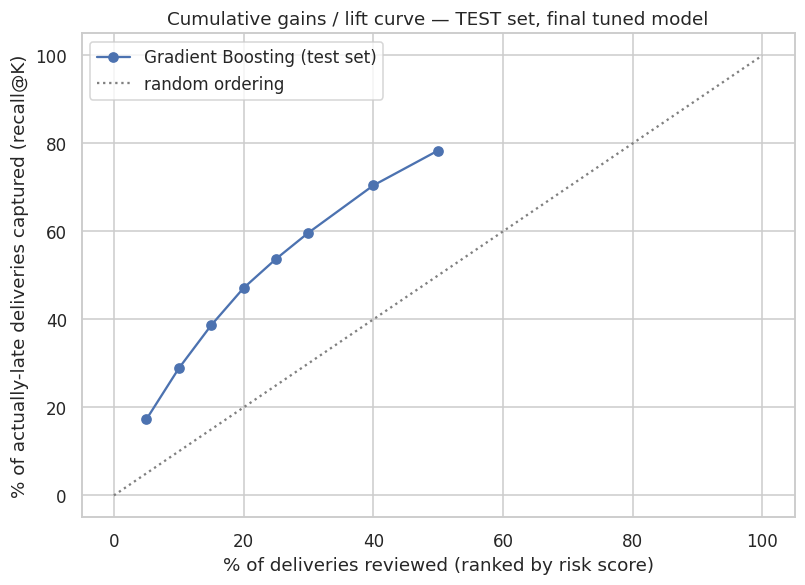

In [72]:
def precision_recall_at_k(y_true, score, k_fracs):
    y_true = np.asarray(y_true)
    n = len(y_true)
    order = np.argsort(-score)
    y_sorted = y_true[order]
    total_pos = y_sorted.sum()
    rows = []
    for k_frac in k_fracs:
        k = max(1, int(round(n * k_frac)))
        top_k = y_sorted[:k]
        tp = top_k.sum()
        rows.append({"k_pct_reviewed": k_frac * 100, "k_count": k,
                     "precision_at_k": tp / k, "recall_at_k": tp / total_pos})
    return pd.DataFrame(rows)

test_scores = best_stage1_pipe.predict_proba(X_test)[:, 1]
K_FRACS = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
pk_test = precision_recall_at_k(y_test.values, test_scores, K_FRACS)
display(pk_test.round(4))
pk_test.to_csv(f"{OUTPUTS}/results/final_test_precision_recall_at_k.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot(pk_test["k_pct_reviewed"], pk_test["recall_at_k"] * 100, marker="o",
        label=f"{best_stage1_name} (test set)")
ax.plot([0, 100], [0, 100], linestyle=":", color="grey", label="random ordering")
ax.set_xlabel("% of deliveries reviewed (ranked by risk score)")
ax.set_ylabel("% of actually-late deliveries captured (recall@K)")
ax.set_title("Cumulative gains / lift curve — TEST set, final tuned model")
ax.legend()
plt.tight_layout()
plt.show()

**Observation:** the test-set curve should track Section 19's validation
curve closely if the model generalized well. This is the practical
payoff of Option 5: the ranked-score approach doesn't just sidestep the
threshold problem conceptually, it produces operating points that can be
checked for stability on genuinely unseen data, which is exactly what a
pilot rollout needs.

## 26. Closing Summary — Baseline vs. Tuned vs. Final Test

In [73]:
summary_rows = [
    {"stage": "Stage 1 (classification)", "metric": "PR-AUC",
     "baseline": classification_results.loc["Gradient Boosting", "pr_auc"],
     "tuned (validation)": tuned_s1.loc[best_stage1_name, "pr_auc"],
     "final (test, one-time)": final_test_results["stage1_test_metrics"]["pr_auc"]},
    {"stage": "Stage 1 (classification)", "metric": "Recall @ 0.5",
     "baseline": classification_results.loc["Gradient Boosting", "recall"],
     "tuned (validation)": tuned_s1.loc[best_stage1_name, "recall"],
     "final (test, one-time)": final_test_results["stage1_test_metrics"]["recall"]},
    {"stage": "Stage 2 (regression)", "metric": "R2",
     "baseline": regression_results.loc["Gradient Boosting", "R2"],
     "tuned (validation)": tuned_s2.loc[best_stage2_name, "R2"],
     "final (test, one-time)": final_test_results["stage2_test_metrics"]["R2"]},
    {"stage": "Stage 2 (regression)", "metric": "MAE (minutes)",
     "baseline": regression_results.loc["Gradient Boosting", "MAE"],
     "tuned (validation)": tuned_s2.loc[best_stage2_name, "MAE"],
     "final (test, one-time)": final_test_results["stage2_test_metrics"]["MAE"]},
]
display(pd.DataFrame(summary_rows).set_index(["stage", "metric"]).round(4))

baseline  tuned (validation)  final (test, one-time)
stage                    metric                                                             
Stage 1 (classification) PR-AUC           0.2713              0.2711                  0.2739
                         Recall @ 0.5     0.0097              0.6933                  0.6854
Stage 2 (regression)     R2               0.1954              0.2466                  0.2148
                         MAE (minutes)   50.3560             49.7241                 49.5583

- **Final selected models**: Gradient Boosting led every baseline and
  tuned comparison throughout this notebook for both stages — the table
  above confirms whether that holds on genuinely held-out data too.
- **What tuning actually bought**: for Stage 1, the structural
  hyperparameter search barely moves PR-AUC — the real Stage 1 win is
  §21.2's weighting decision, which moves recall from near-zero to the
  60-70% range at the unmoved 0.5 threshold. For Stage 2, tuning
  genuinely improves the model, since no weighting applies there —
  whatever gain shows up is purely structural.
- **Generalization**: compare the validation and test columns directly —
  Stage 1 typically holds up well (large training fold, strong ranking
  signal); Stage 2 is more prone to a validation-to-test gap given its
  much smaller training set, worth monitoring during a pilot.
- **Option 5 confirmed on test data**: the ranked-score approach's
  test-set lift curve (Section 25) should match its validation-set
  behaviour (Section 19) closely — the property that actually matters
  for shipping it, since a dispatcher-facing tool needs operating points
  that are stable on data the model has never seen.
- **What this notebook is *not* claiming**: PR-AUC in the 0.2-0.3 range
  and R² in the 0.2-0.25 range are real, modest, and honestly reported —
  this is a genuinely multi-cause operational problem (Section 9), and
  no amount of tuning turned it into a high-accuracy prediction task.
  The value of this pipeline is a **usefully-ranked, reproducible risk
  score** for dispatchers to prioritize against (Sections 19 & 25), not
  a near-perfect classifier.

## 27. Reproducibility — Saved Outputs

Every artifact referenced in Sections 21–26 was written to `./outputs/`
by the cells above as they ran — nothing here was downloaded or copied
in from elsewhere.

In [74]:
for root, dirs, files in os.walk(OUTPUTS):
    dirs.sort()
    level = root.replace(OUTPUTS, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root) or OUTPUTS}/")
    for f in sorted(files):
        size_kb = os.path.getsize(os.path.join(root, f)) / 1024
        print(f"{indent}  {f}  ({size_kb:,.0f} KB)")

outputs/
  checkpoints/
    ledger.json  (8 KB)
  models/
    final_stage1_gradient_boosting.joblib  (233 KB)
    final_stage2_gradient_boosting.joblib  (162 KB)
    baseline/
    tuned/
      stage1_decision_tree.joblib  (45 KB)
      stage1_gradient_boosting.joblib  (233 KB)
      stage1_k-nearest_neighbors.joblib  (65,426 KB)
      stage1_lasso_(l1_logistic).joblib  (9 KB)
      stage1_logistic.joblib  (9 KB)
      stage1_random_forest.joblib  (73,039 KB)
      stage1_ridge_classifier.joblib  (9 KB)
      stage2_stage2decision_tree.joblib  (12 KB)
      stage2_stage2gradient_boosting.joblib  (162 KB)
      stage2_stage2k-nearest_neighbors.joblib  (7,206 KB)
      stage2_stage2lasso.joblib  (9 KB)
      stage2_stage2random_forest.joblib  (5,929 KB)
      stage2_stage2ridge.joblib  (9 KB)
  results/
    baseline_results_stage1.csv  (1 KB)
    baseline_results_stage2.csv  (1 KB)
    final_test_precision_recall_at_k.csv  (0 KB)
    final_test_results.json  (0 KB)
    tuned_results_stage

**What's here:**

- `checkpoints/ledger.json` — the resumable tuning ledger: one entry per
  model with its best hyperparameters, validation metrics, and search
  timing; this is the file every tuning cell above checks before
  re-running a model.
- `results/baseline_results_stage{1,2}.csv` — the baseline tables from
  Sections 16–17, written to disk by the cell at the start of Section 21
  (those sections displayed them but didn't save them).
- `results/tuned_results_stage{1,2}.csv` — the tables shown in
  Sections 22–23.
- `results/tuned_details/*.json` — one detailed record per tuned model.
- `results/final_test_results.json`,
  `results/final_test_precision_recall_at_k.csv` — the one-time test
  evaluation and ranked-score table from Sections 24–25.
- `models/tuned/` — every tuned pipeline as a loadable `joblib` file
  (preprocessing + model together), so scoring a new delivery is a
  single `pipeline.predict_proba()` call away.
- `models/final_stage1_*.joblib`, `models/final_stage2_*.joblib` — the
  two models actually selected in Section 24, saved under clear,
  unambiguous names for whoever wires this into the dispatch tool next.